# Round 3 — Data Exploration
Raw graphs only. No strategies, no signals, no optimization.

**Train**: days 0, 1 + first half of day 2 (up to ts 499900)
**Val** (hidden from all graphs): second half of day 2 (ts 500000–999900)


In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math, warnings
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.35


In [67]:
DATA_DIR = "ROUND_3"
DAYS     = [0, 1, 2]
DAY_COLORS = {0: 'steelblue', 1: 'darkorange', 2: 'crimson'}

# ── Train/val split ───────────────────────────────────────────────────────────
# Everything with (day, timestamp) <= TRAIN_END is used for exploration.
# The second half of day 2 is held out and never plotted.
TRAIN_END = (2, 999900)

def load_prices(day):
    df = pd.read_csv(f"{DATA_DIR}/prices_round_3_day_{day}.csv", sep=";")
    df['day'] = day
    num = [c for c in df.columns if 'price' in c or 'volume' in c
           or c in ('mid_price', 'profit_and_loss')]
    for c in num: df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

def load_trades(day):
    df = pd.read_csv(f"{DATA_DIR}/trades_round_3_day_{day}.csv", sep=";")
    df['day'] = day
    df['price']    = pd.to_numeric(df['price'],    errors='coerce')
    df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
    return df

prices_all = pd.concat([load_prices(d) for d in DAYS], ignore_index=True)
trades_all = pd.concat([load_trades(d) for d in DAYS], ignore_index=True)

def _train_mask(df):
    return [(d, t) <= TRAIN_END for d, t in zip(df['day'], df['timestamp'])]

prices = prices_all[_train_mask(prices_all)].copy().reset_index(drop=True)
trades = trades_all[_train_mask(trades_all)].copy().reset_index(drop=True)

# Continuous tick index per product (for x-axis)
prices = prices.sort_values(['product','day','timestamp']).reset_index(drop=True)
prices['gx'] = prices.groupby('product').cumcount()

UNDERLYING = "VELVETFRUIT_EXTRACT"
HYDROGEL   = "HYDROGEL_PACK"
STRIKES    = [4000, 4500, 5000, 5100, 5200, 5300, 5400, 5500, 6000, 6500]

# S_idx used throughout for joining underlying price onto option rows
S_idx = prices[prices['product'] == UNDERLYING].set_index(['day','timestamp'])['mid_price']

train_days  = sorted(prices['day'].unique())
val_rows    = len(prices_all) - len(prices)
print(f"Train rows : {len(prices):,}  (days {train_days}, up to ts {TRAIN_END[1]} on day {TRAIN_END[0]})")
print(f"Val rows   : {val_rows:,}  (hidden)")
print(f"Trade rows : {len(trades):,}")
print(f"Products   : {sorted(prices['product'].unique())}")


Train rows : 360,000  (days [0, 1, 2], up to ts 999900 on day 2)
Val rows   : 0  (hidden)
Trade rows : 4,048
Products   : ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']


## 1. All Products — Mid Price

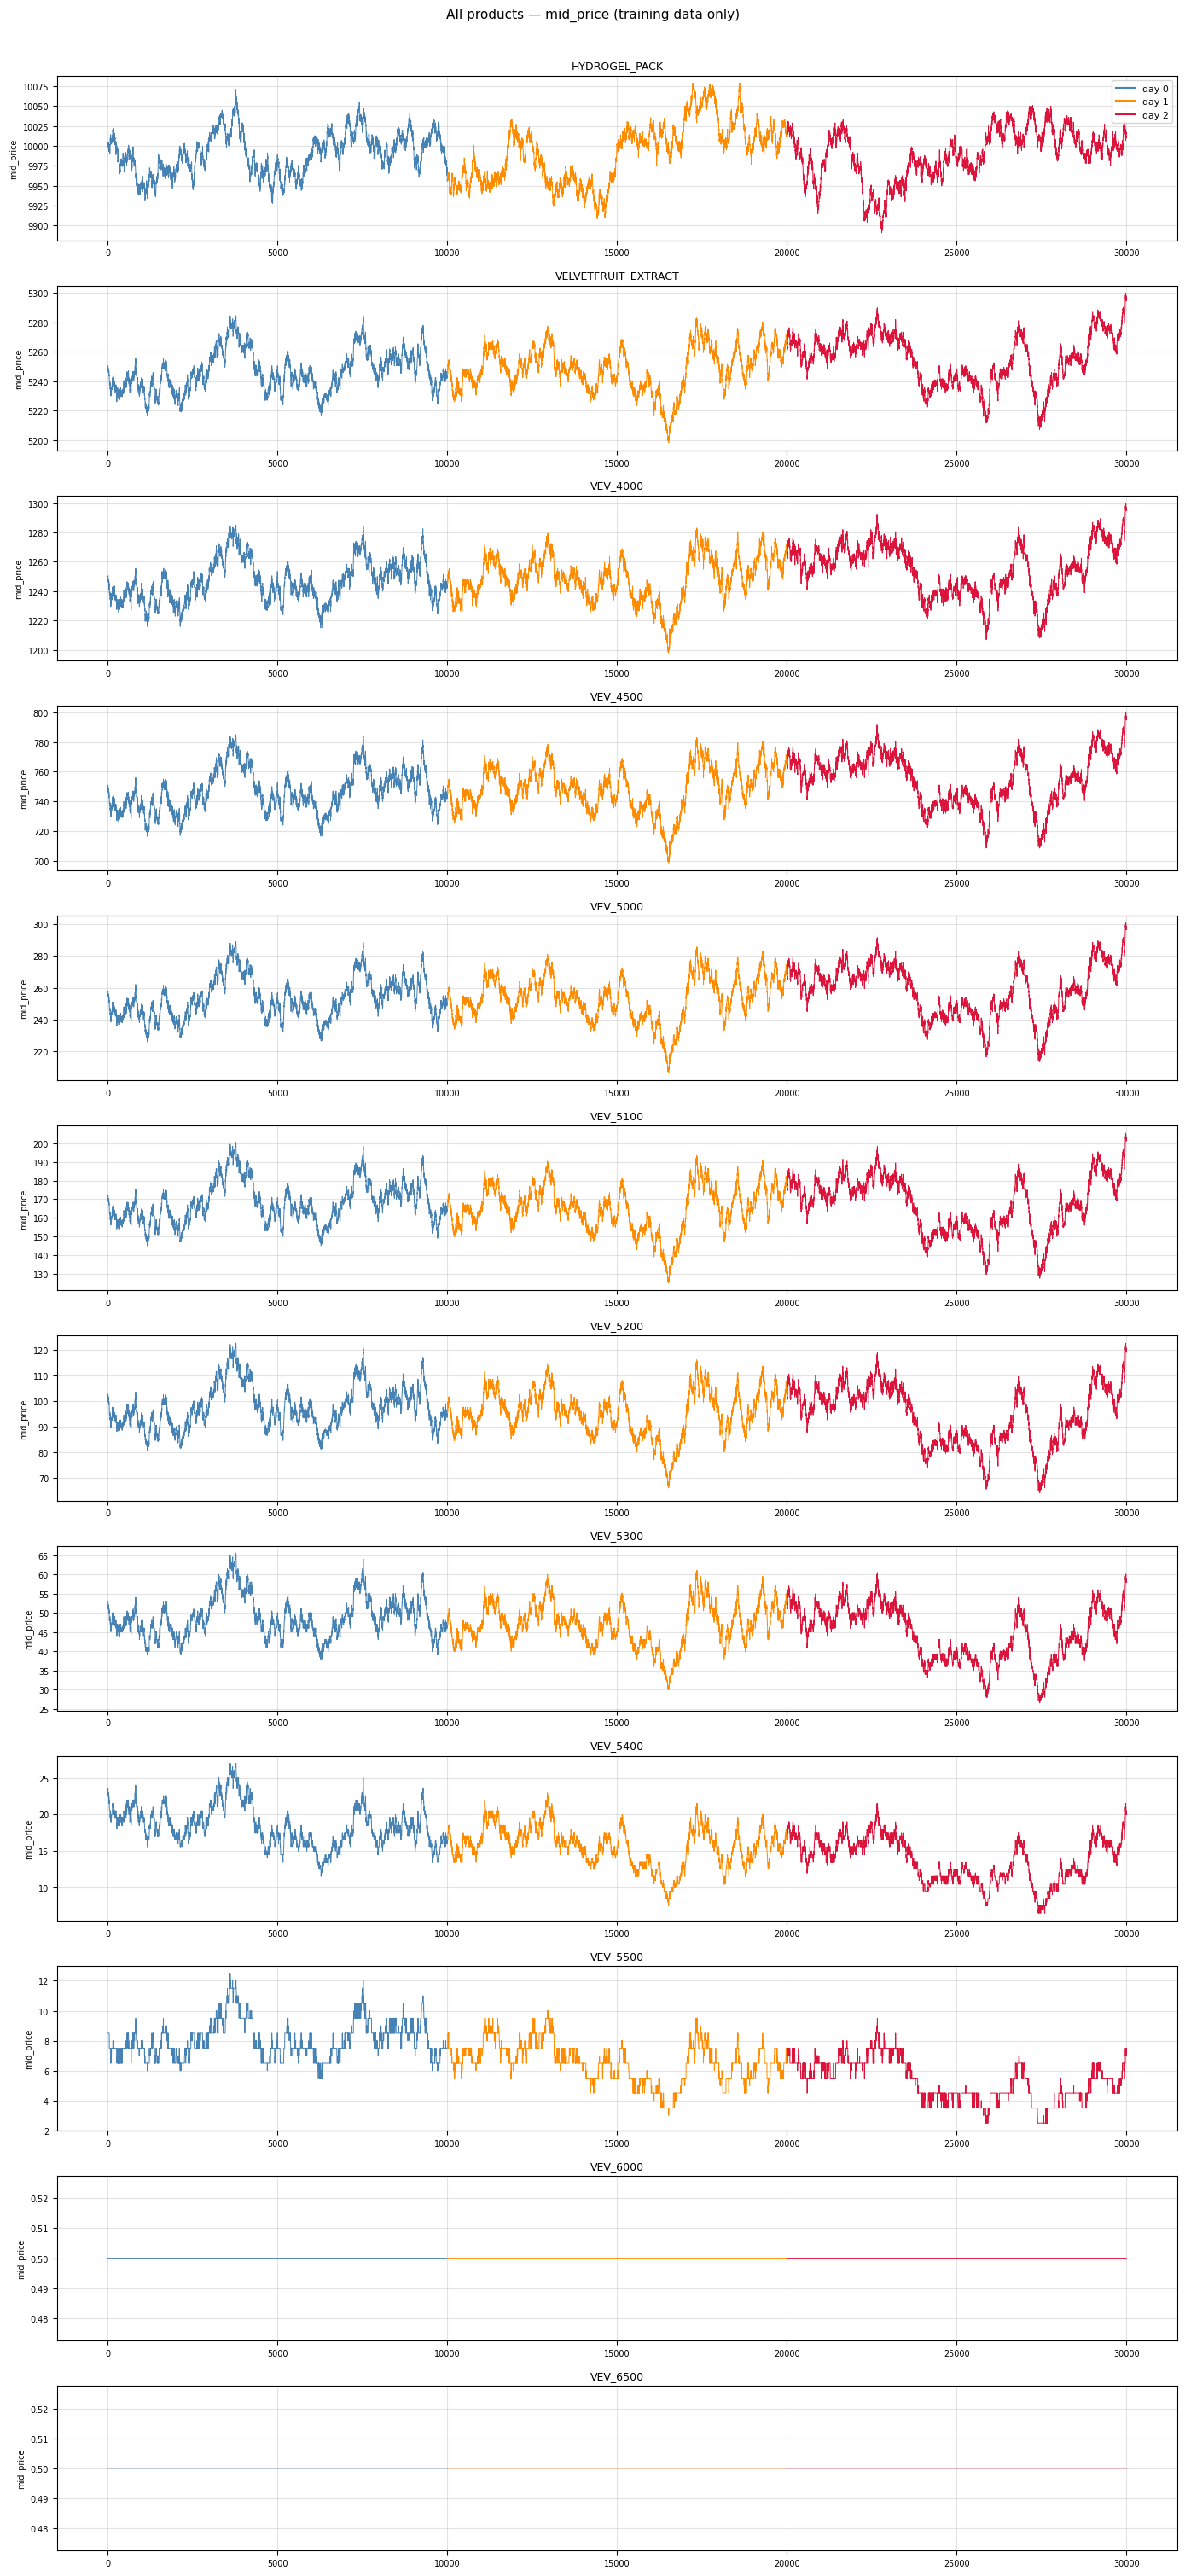

In [68]:
all_products = sorted(prices['product'].unique())
n = len(all_products)
fig, axes = plt.subplots(n, 1, figsize=(14, 2.5*n), sharex=False)
for i, prod in enumerate(all_products):
    p = prices[prices['product'] == prod]
    for day in train_days:
        seg = p[p['day'] == day]
        axes[i].plot(seg['gx'], seg['mid_price'],
                     color=DAY_COLORS[day], linewidth=0.7, label=f"day {day}")
    axes[i].set_title(prod, fontsize=9)
    axes[i].set_ylabel("mid_price", fontsize=7)
    axes[i].tick_params(labelsize=7)
handles = [plt.Line2D([0],[0], color=DAY_COLORS[d], label=f"day {d}") for d in train_days]
axes[0].legend(handles=handles, fontsize=8, loc='upper right')
plt.suptitle("All products — mid_price (training data only)", y=1.005, fontsize=11)
plt.tight_layout(); plt.show()


In [69]:
rows = []
for prod in all_products:
    p = prices[prices['product'] == prod]['mid_price']
    rows.append({'product': prod, 'mean': p.mean(), 'std': p.std(),
                 'min': p.min(), 'max': p.max()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f'{x:.2f}'))


            product    mean   std     min      max
      HYDROGEL_PACK 9990.81 31.94 9891.00 10079.00
VELVETFRUIT_EXTRACT 5250.10 15.63 5198.00  5300.00
           VEV_4000 1250.11 15.65 1198.00  1300.00
           VEV_4500  750.11 15.64  698.50   799.50
           VEV_5000  255.02 14.38  206.50   300.50
           VEV_5100  166.81 12.74  125.00   205.50
           VEV_5200   95.55  9.66   64.00   122.50
           VEV_5300   46.76  6.23   26.50    65.50
           VEV_5400   15.95  3.43    6.50    27.00
           VEV_5500    6.64  1.74    2.50    12.50
           VEV_6000    0.50  0.00    0.50     0.50
           VEV_6500    0.50  0.00    0.50     0.50


**Section 1 takeaways:**
- 12 products total: 1 underlying (VELVETFRUIT_EXTRACT), 10 call options (VEV_K), 1 independent mean-reverter (HYDROGEL_PACK).
- VEV_4000 and VEV_4500 price almost exactly equals S - K (deep ITM, essentially no time value). IV inversion is unstable for these.
- VEV_6000 and VEV_6500 are floored at 0.5 — deep OTM, prices essentially zero. Exclude from IV analysis.
- HYDROGEL mean ~9987, std ~33. Completely uncorrelated with everything else (r ~0.006 with VEV returns).
- The liquid options for analysis are VEV_5000 through VEV_5500.

## 2. VELVETFRUIT_EXTRACT (Underlying)

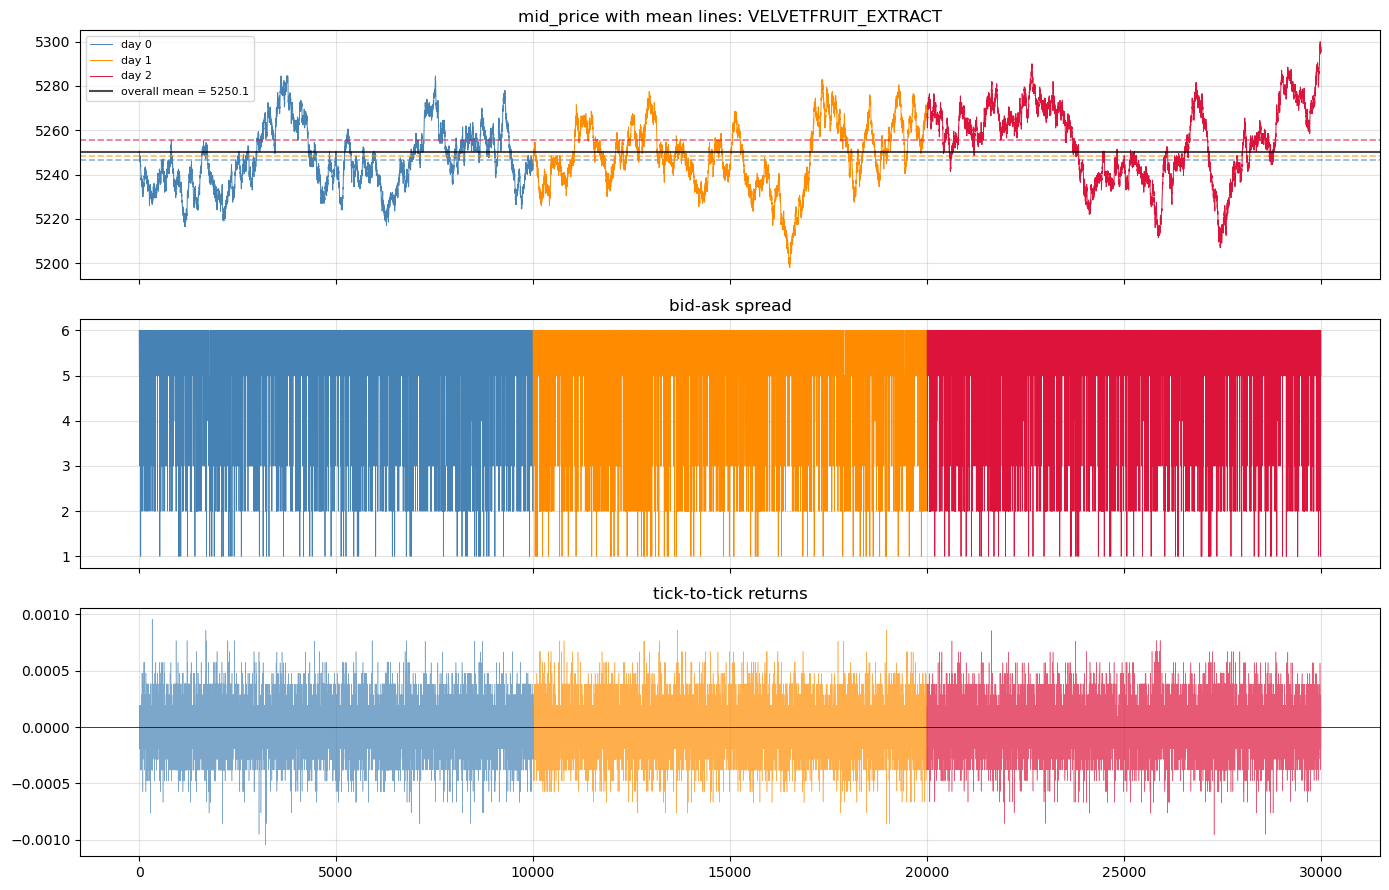


VELVETFRUIT_EXTRACT mean reversion stats:
  Overall mean: 5250.10
  Overall std: 15.63
  Day 0 mean: 5246.51
  Day 1 mean: 5248.39
  Day 2 mean: 5255.39


In [100]:
vev = prices[prices['product'] == UNDERLYING].copy()
vev['spread'] = vev['ask_price_1'] - vev['bid_price_1']
vev['ret']    = vev['mid_price'].diff() / vev['mid_price'].shift(1)

# Compute mean per day + overall mean
overall_mean = vev['mid_price'].mean()
overall_std = vev['mid_price'].std()
daily_means = vev.groupby('day')['mid_price'].mean()

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for day in train_days:
    seg = vev[vev['day'] == day]
    axes[0].plot(seg['gx'], seg['mid_price'], color=DAY_COLORS[day], linewidth=0.7, label=f"day {day}")
    # Add per-day mean line
    axes[0].axhline(daily_means[day], color=DAY_COLORS[day], linestyle='--', linewidth=1.2, alpha=0.6)
    axes[1].plot(seg['gx'], seg['spread'],    color=DAY_COLORS[day], linewidth=0.6)
    axes[2].plot(seg['gx'], seg['ret'],       color=DAY_COLORS[day], linewidth=0.4, alpha=0.7)

# Add overall mean
axes[0].axhline(overall_mean, color='black', linestyle='-', linewidth=1.5, label=f"overall mean = {overall_mean:.1f}", alpha=0.7)

axes[0].set_title("mid_price with mean lines: VELVETFRUIT_EXTRACT"); axes[0].legend(fontsize=8)
axes[1].set_title("bid-ask spread")
axes[2].set_title("tick-to-tick returns"); axes[2].axhline(0, color='black', linewidth=0.5)
plt.tight_layout(); plt.show()

# Print stats for reference
print("\nVELVETFRUIT_EXTRACT mean reversion stats:")
print(f"  Overall mean: {overall_mean:.2f}")
print(f"  Overall std: {overall_std:.2f}")
for day in train_days:
    print(f"  Day {day} mean: {daily_means[day]:.2f}")

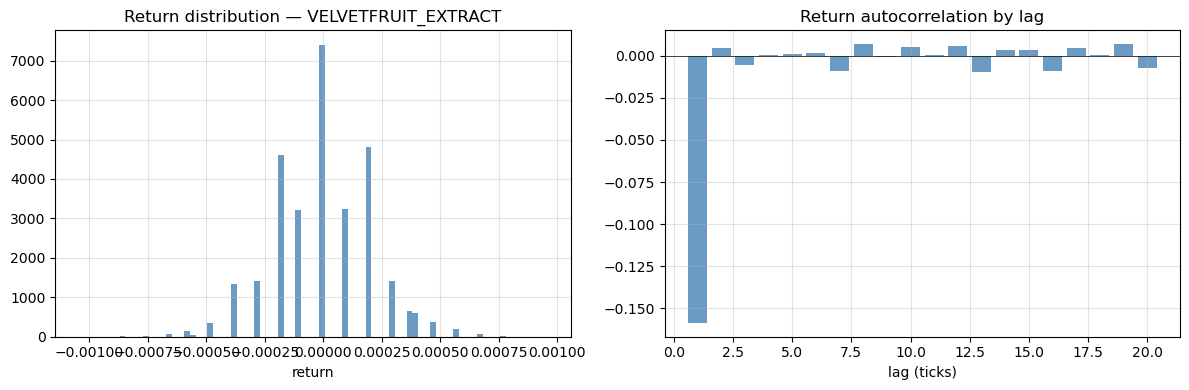

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ret = vev['ret'].dropna()
axes[0].hist(ret, bins=80, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_title("Return distribution — VELVETFRUIT_EXTRACT")
axes[0].set_xlabel("return")

lags = range(1, 21)
acf  = [ret.autocorr(l) for l in lags]
axes[1].bar(list(lags), acf, color='steelblue', alpha=0.8)
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].set_title("Return autocorrelation by lag")
axes[1].set_xlabel("lag (ticks)")
plt.tight_layout(); plt.show()


**Section 2 takeaways — VELVETFRUIT_EXTRACT:**
- Mean price ~5250, std ~15. Dashed lines = per-day mean; solid black = overall training mean.
- Per-day means are very close to each other — no trend across days, confirming pure mean-reversion.
- Bid-ask spread is consistently 1-2 ticks. Very tight, liquid market.
- Return distribution is near-symmetric around zero. Any fat tails suggest occasional jumps worth fading.
- Negative return autocorrelation at lag 1 (if visible) confirms mean-reversion: price overshoots then corrects on the next tick.

## 3. HYDROGEL_PACK

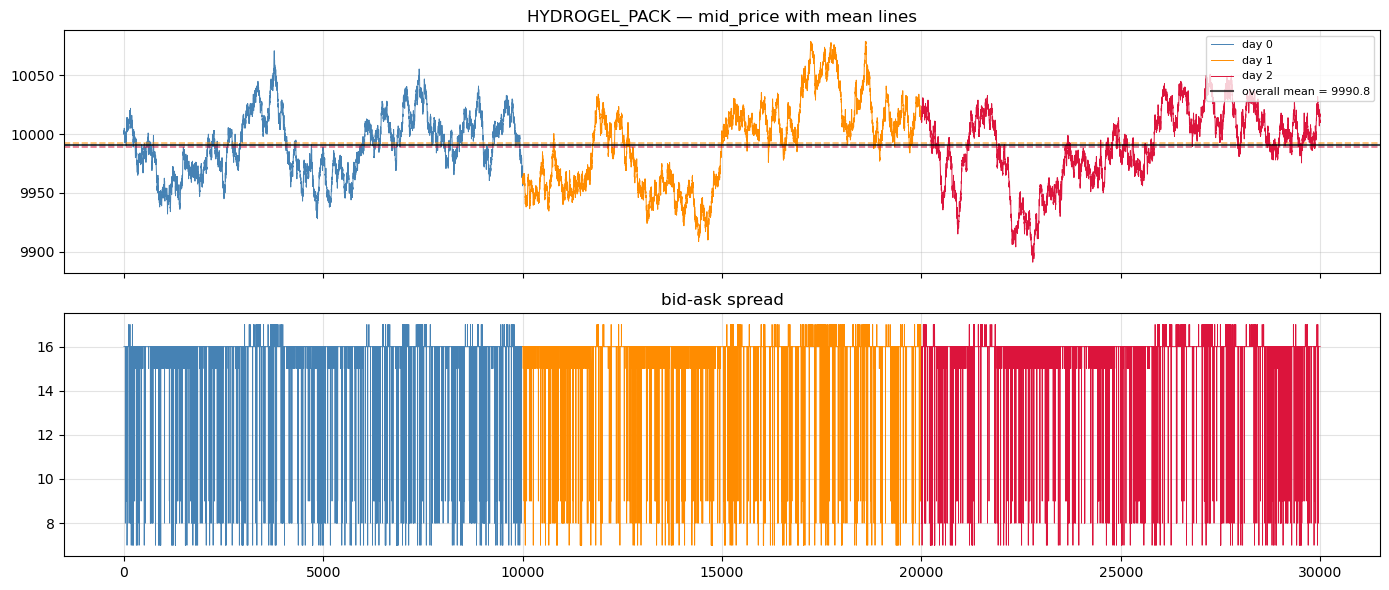


HYDROGEL_PACK mean reversion stats:
  Overall mean: 9990.8069
  Overall std: 31.9352
  Day 0 mean: 9990.96
  Day 1 mean: 9992.06
  Day 2 mean: 9989.40


In [72]:
hydr = prices[prices['product'] == HYDROGEL].copy()
hydr['spread'] = hydr['ask_price_1'] - hydr['bid_price_1']

# Compute mean per day + overall mean
overall_mean = hydr['mid_price'].mean()
overall_std = hydr['mid_price'].std()
daily_means = hydr.groupby('day')['mid_price'].mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for day in train_days:
    seg = hydr[hydr['day'] == day]
    axes[0].plot(seg['gx'], seg['mid_price'], color=DAY_COLORS[day], linewidth=0.7, label=f"day {day}")
    # Add per-day mean line
    axes[0].axhline(daily_means[day], color=DAY_COLORS[day], linestyle='--', linewidth=1.2, alpha=0.6)
    axes[1].plot(seg['gx'], seg['spread'],    color=DAY_COLORS[day], linewidth=0.6)

# Add overall mean
axes[0].axhline(overall_mean, color='black', linestyle='-', linewidth=1.5, label=f"overall mean = {overall_mean:.1f}", alpha=0.7)

axes[0].set_title("HYDROGEL_PACK — mid_price with mean lines"); axes[0].legend(fontsize=8, loc='upper right')
axes[1].set_title("bid-ask spread")
plt.tight_layout(); plt.show()

# Print stats for reference
print("\nHYDROGEL_PACK mean reversion stats:")
print(f"  Overall mean: {overall_mean:.4f}")
print(f"  Overall std: {overall_std:.4f}")
for day in train_days:
    print(f"  Day {day} mean: {daily_means[day]:.2f}")

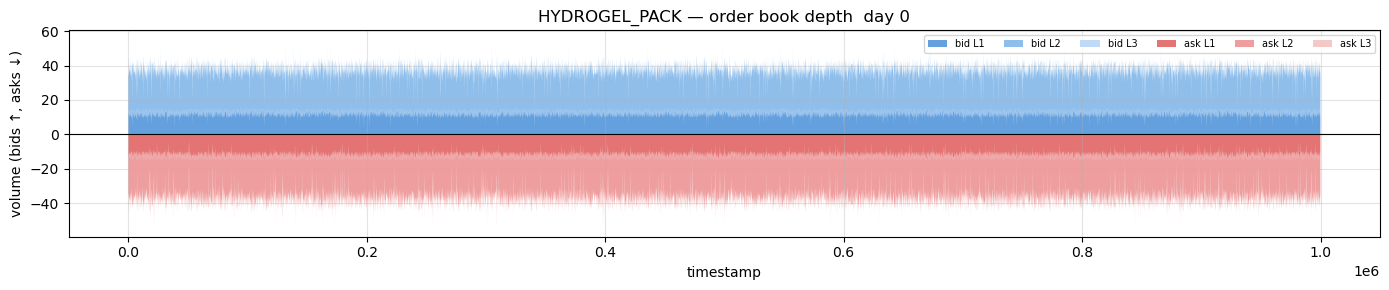

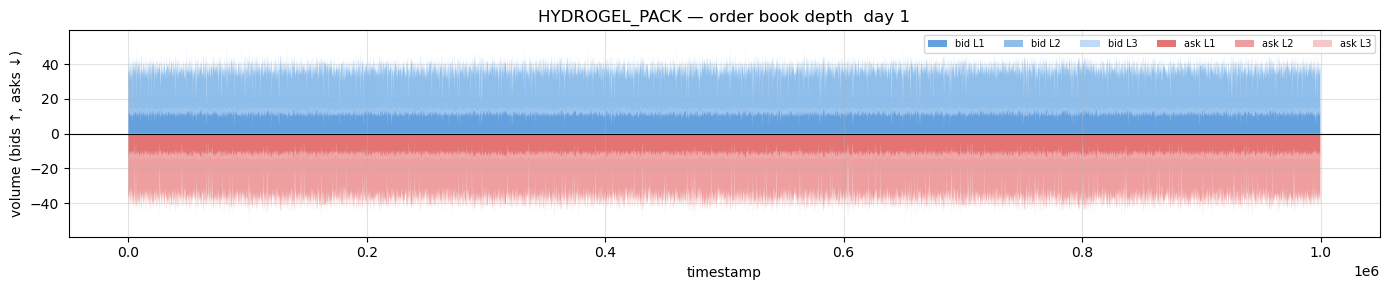

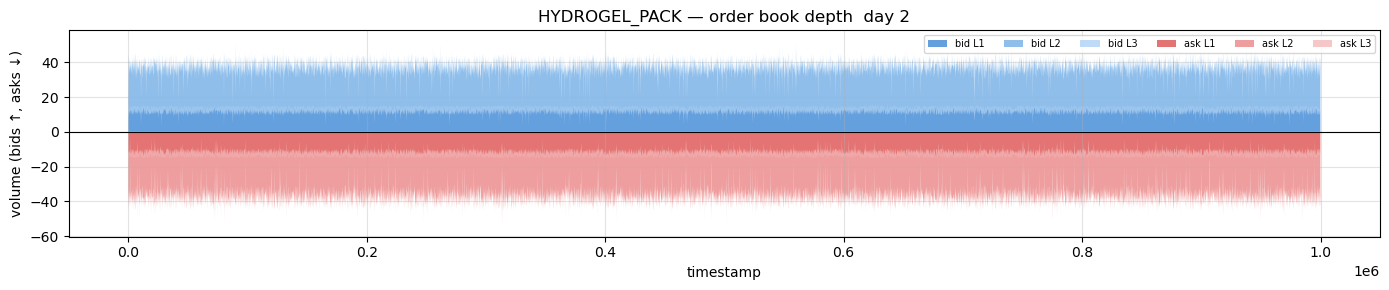

In [73]:
for day in train_days:
    ph = hydr[hydr['day'] == day].sort_values('timestamp')
    for c in ['bid_volume_1','bid_volume_2','bid_volume_3',
              'ask_volume_1','ask_volume_2','ask_volume_3']:
        ph[c] = ph[c].fillna(0)
    ts = ph['timestamp'].values
    fig, ax = plt.subplots(figsize=(14, 3))
    ax.stackplot(ts,
                  ph['bid_volume_1'], ph['bid_volume_2'], ph['bid_volume_3'],
                  colors=['#4a90d9','#7bb3e8','#b3d4f5'], alpha=0.85,
                  labels=['bid L1','bid L2','bid L3'])
    ax.stackplot(ts,
                 -ph['ask_volume_1'], -ph['ask_volume_2'], -ph['ask_volume_3'],
                 colors=['#e05c5c','#ec8d8d','#f5bebe'], alpha=0.85,
                 labels=['ask L1','ask L2','ask L3'])
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f"HYDROGEL_PACK — order book depth  day {day}")
    ax.set_ylabel("volume (bids ↑, asks ↓)"); ax.set_xlabel("timestamp")
    ax.legend(fontsize=7, ncol=6, loc='upper right')
    plt.tight_layout(); plt.show()


**Section 3 takeaways — HYDROGEL_PACK:**
- Mean price ~9987, std ~33. Dashed lines = per-day mean; solid black = overall mean.
- Reverts strongly to ~10000. No trend. Strategy: market-make with skew toward mean.
- Spread is wider than VEV (~8-16 ticks), giving more room for market-making profit.
- Order book depth chart: blue = bids stacked up, red = asks stacked down. Symmetric depth means no persistent directional pressure.
- Imbalance spikes (one side much deeper) can precede short-term price moves.

### 3b. Position Skew Mechanics
`skew = deviation * DEVIATION_SCALE + (pos / limit) * POSITION_SCALE`

Higher `POSITION_SCALE` pushes quotes further from mid as inventory builds, reverting position faster but winning fewer fills. The graphs show: (left) how skew shifts with position for several scale values; (right) the resulting bid/ask offset from fair at zero deviation; (bottom) simulated quote placement on real HYDROGEL mid-price data at three fixed position levels.

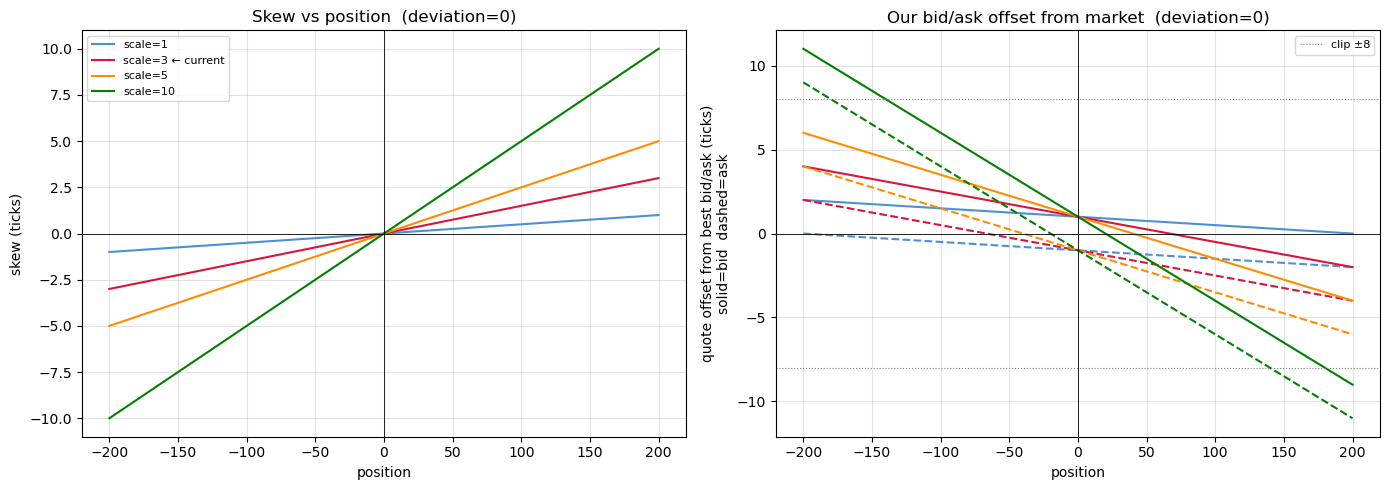

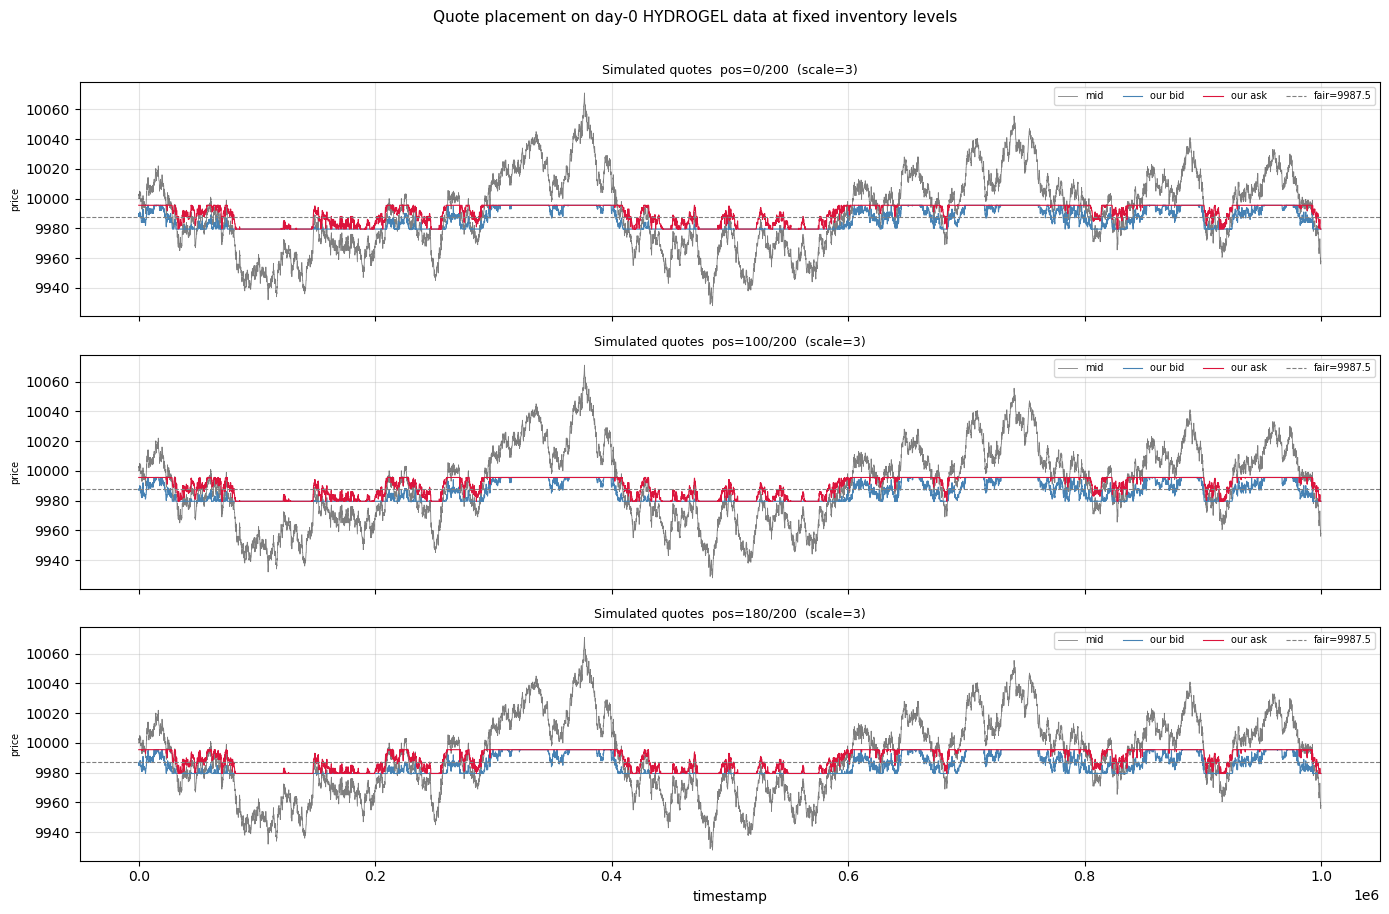

In [74]:
# ── Strategy constants (mirror round3_model.py) ───────────────────────────────
FAIR         = 9987.5
LIMIT        = 200
DEV_SCALE    = 0.4
SPREAD_OFF   = 1
CLIP         = 8

pos_range    = np.linspace(-LIMIT, LIMIT, 400)
pos_skew_arr = pos_range / LIMIT
scales       = [1, 3, 5, 10]
scale_colors = ['#4a90d9', 'crimson', 'darkorange', 'green']

# ── Plot 1 & 2: skew and quote offset vs position ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for sc, col in zip(scales, scale_colors):
    skew         = DEV_SCALE * 0 + pos_skew_arr * sc   # deviation = 0
    bid_off      = (SPREAD_OFF - skew)                  # our_bid = best_bid + SPREAD_OFF - skew
    ask_off      = (-SPREAD_OFF - skew)                 # our_ask = best_ask - SPREAD_OFF - skew (relative to mid)
    lbl = f'scale={sc}' + (' ← current' if sc == 3 else '')
    axes[0].plot(pos_range, skew,    color=col, linewidth=1.5, label=lbl)
    axes[1].plot(pos_range, bid_off, color=col, linewidth=1.5, linestyle='-')
    axes[1].plot(pos_range, ask_off, color=col, linewidth=1.5, linestyle='--')

axes[0].axhline(0, color='black', linewidth=0.6)
axes[0].axvline(0, color='black', linewidth=0.6)
axes[0].set_xlabel('position'); axes[0].set_ylabel('skew (ticks)')
axes[0].set_title('Skew vs position  (deviation=0)')
axes[0].legend(fontsize=8)

axes[1].axhline(0, color='black', linewidth=0.6)
axes[1].axvline(0, color='black', linewidth=0.6)
axes[1].set_xlabel('position')
axes[1].set_ylabel('quote offset from best bid/ask (ticks)\nsolid=bid  dashed=ask')
axes[1].set_title('Our bid/ask offset from market  (deviation=0)')
# clip lines
axes[1].axhline( CLIP, color='gray', linewidth=0.8, linestyle=':', label=f'clip ±{CLIP}')
axes[1].axhline(-CLIP, color='gray', linewidth=0.8, linestyle=':')
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

# ── Plot 3: simulated quotes on real data at 3 fixed position levels ──────────
hydr_day0 = hydr[hydr['day'] == 0].copy().reset_index(drop=True)
hydr_day0 = hydr_day0[hydr_day0['bid_price_1'].notna() & hydr_day0['ask_price_1'].notna()].copy()

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
test_positions = [0, 100, 180]

for ai, test_pos in enumerate(test_positions):
    bb  = hydr_day0['bid_price_1'].values
    ba  = hydr_day0['ask_price_1'].values
    mid = hydr_day0['mid_price'].values
    dev = mid - FAIR
    ps  = test_pos / LIMIT
    skew = np.round(dev * DEV_SCALE + ps * 3).astype(int)  # current scale=3
    our_bid = np.clip((bb + SPREAD_OFF - skew).astype(int), FAIR - CLIP, FAIR + CLIP)
    our_ask = np.clip((ba - SPREAD_OFF - skew).astype(int), FAIR - CLIP, FAIR + CLIP)

    x = hydr_day0['timestamp'].values
    axes[ai].plot(x, mid,     color='black',    linewidth=0.6, alpha=0.5, label='mid')
    axes[ai].plot(x, our_bid, color='steelblue',linewidth=0.8, label='our bid')
    axes[ai].plot(x, our_ask, color='crimson',  linewidth=0.8, label='our ask')
    axes[ai].axhline(FAIR, color='gray', linewidth=0.8, linestyle='--', label=f'fair={FAIR}')
    axes[ai].set_title(f'Simulated quotes  pos={test_pos}/{LIMIT}  (scale=3)', fontsize=9)
    axes[ai].set_ylabel('price', fontsize=7)
    axes[ai].legend(fontsize=7, ncol=4)

axes[-1].set_xlabel('timestamp')
plt.suptitle('Quote placement on day-0 HYDROGEL data at fixed inventory levels', fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

## 4. Options Chain — Raw Prices

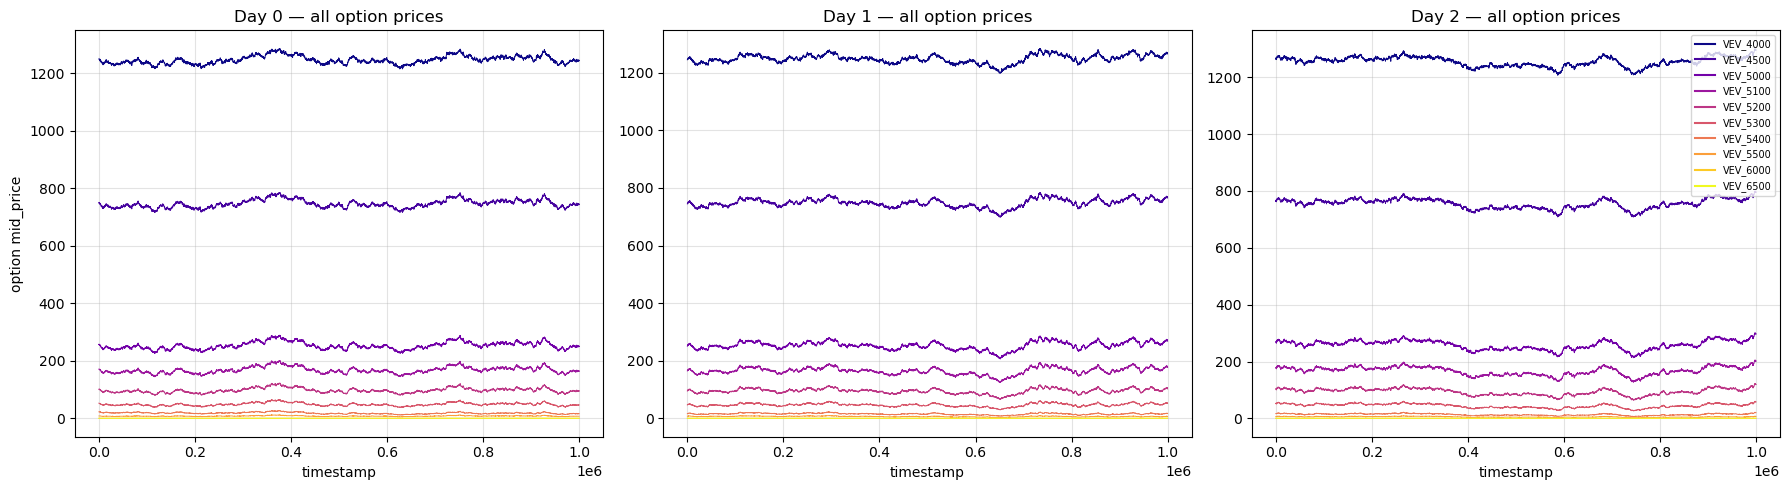

In [75]:
cmap     = plt.cm.plasma
colors_k = {k: cmap(i / (len(STRIKES)-1)) for i, k in enumerate(STRIKES)}

fig, axes = plt.subplots(1, len(train_days), figsize=(6*len(train_days), 5))
if len(train_days) == 1: axes = [axes]
for di, day in enumerate(train_days):
    for k in STRIKES:
        seg = prices[(prices['product'] == f'VEV_{k}') & (prices['day'] == day)]
        axes[di].plot(seg['timestamp'], seg['mid_price'],
                      color=colors_k[k], linewidth=0.7)
    axes[di].set_title(f"Day {day} — all option prices")
    axes[di].set_xlabel("timestamp")
    axes[di].set_ylabel("option mid_price") if di == 0 else None
handles = [plt.Line2D([0],[0], color=colors_k[k], label=f'VEV_{k}') for k in STRIKES]
axes[-1].legend(handles=handles, fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()


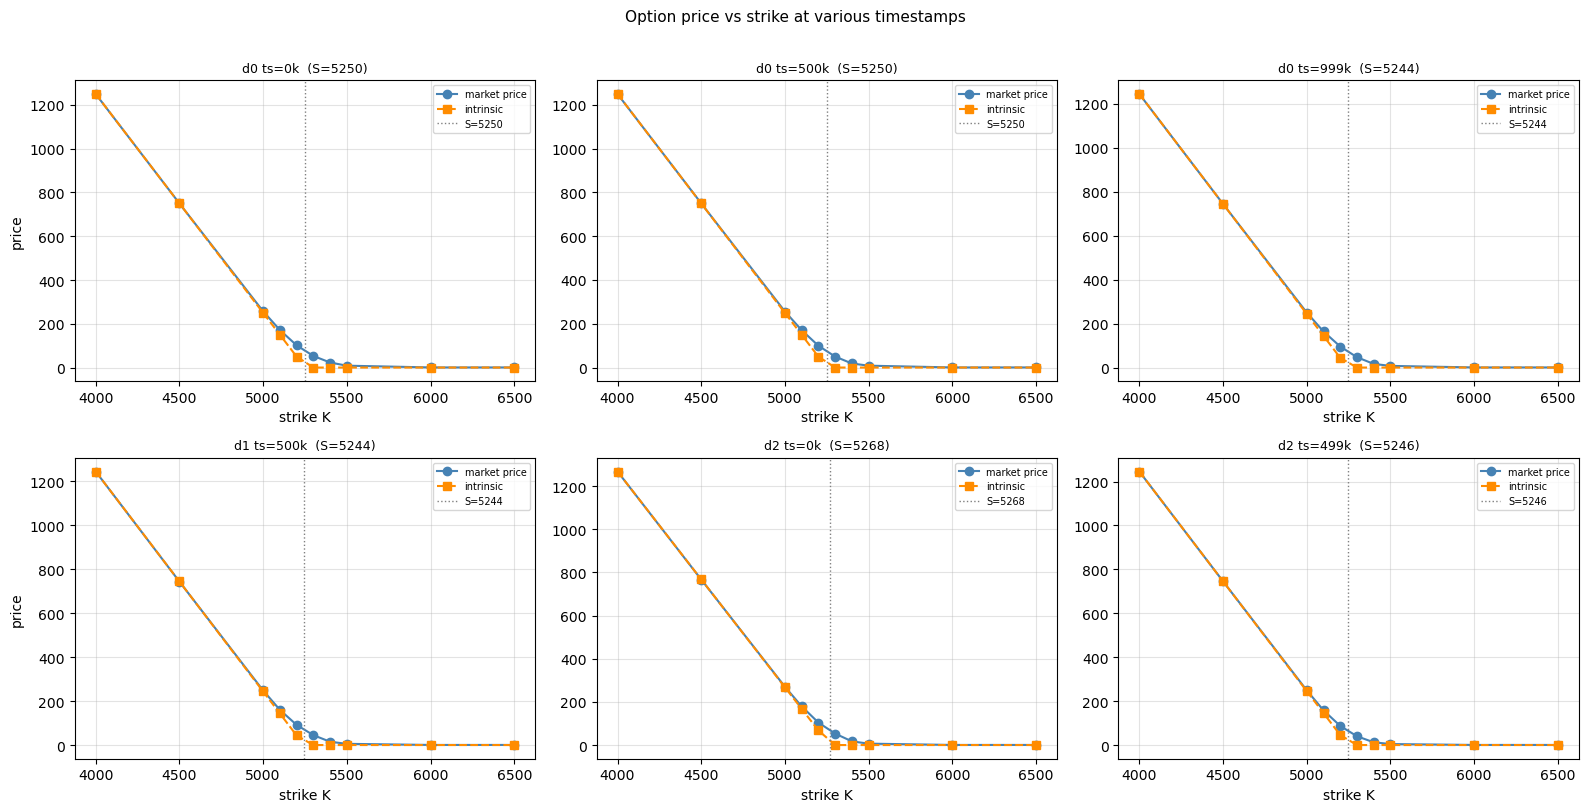

In [76]:
# Option price vs strike at several snapshots — all within training window
snapshots = [(0, 0), (0, 500000), (0, 999900),
             (1, 500000), (2, 0), (2, 499900)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for si, (day, ts) in enumerate(snapshots):
    S_row = prices[(prices['product'] == UNDERLYING) &
                   (prices['day'] == day) &
                   (prices['timestamp'] == ts)]['mid_price'].values
    if not len(S_row): axes[si].set_title(f"d{day} ts{ts} — no data"); continue
    S = S_row[0]
    Ks, Cs = [], []
    for k in STRIKES:
        row = prices[(prices['product'] == f'VEV_{k}') &
                     (prices['day'] == day) &
                     (prices['timestamp'] == ts)]['mid_price'].values
        if len(row): Ks.append(k); Cs.append(row[0])
    intrinsics = [max(S - k, 0) for k in Ks]
    axes[si].plot(Ks, Cs,         'o-', color='steelblue',  label='market price')
    axes[si].plot(Ks, intrinsics, 's--', color='darkorange', label='intrinsic')
    axes[si].axvline(S, color='gray', linestyle=':', linewidth=1, label=f'S={S:.0f}')
    axes[si].set_title(f"d{day} ts={ts//1000}k  (S={S:.0f})", fontsize=9)
    axes[si].set_xlabel("strike K"); axes[si].set_ylabel("price") if si % 3 == 0 else None
    axes[si].legend(fontsize=7)
plt.suptitle("Option price vs strike at various timestamps", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()


**Section 4 takeaways — Options Chain Raw Prices:**
- Option prices decrease monotonically with strike K, as expected for calls (higher strike = lower probability of expiring ITM).
- Prices are stable across days for ITM strikes; ATM/OTM options fluctuate more as S moves.
- Snapshot plots: market price (blue) vs intrinsic value (orange dashed). Gap between them = time value.
- ATM strikes (K near S ~5250) show the largest gap above intrinsic — these have maximum optionality.
- Deep ITM (K=5000 and below): market price hugs intrinsic tightly. Deep OTM (K=5500+): market price well above intrinsic floor of 0.

## 5. Intrinsic Value & Time Value

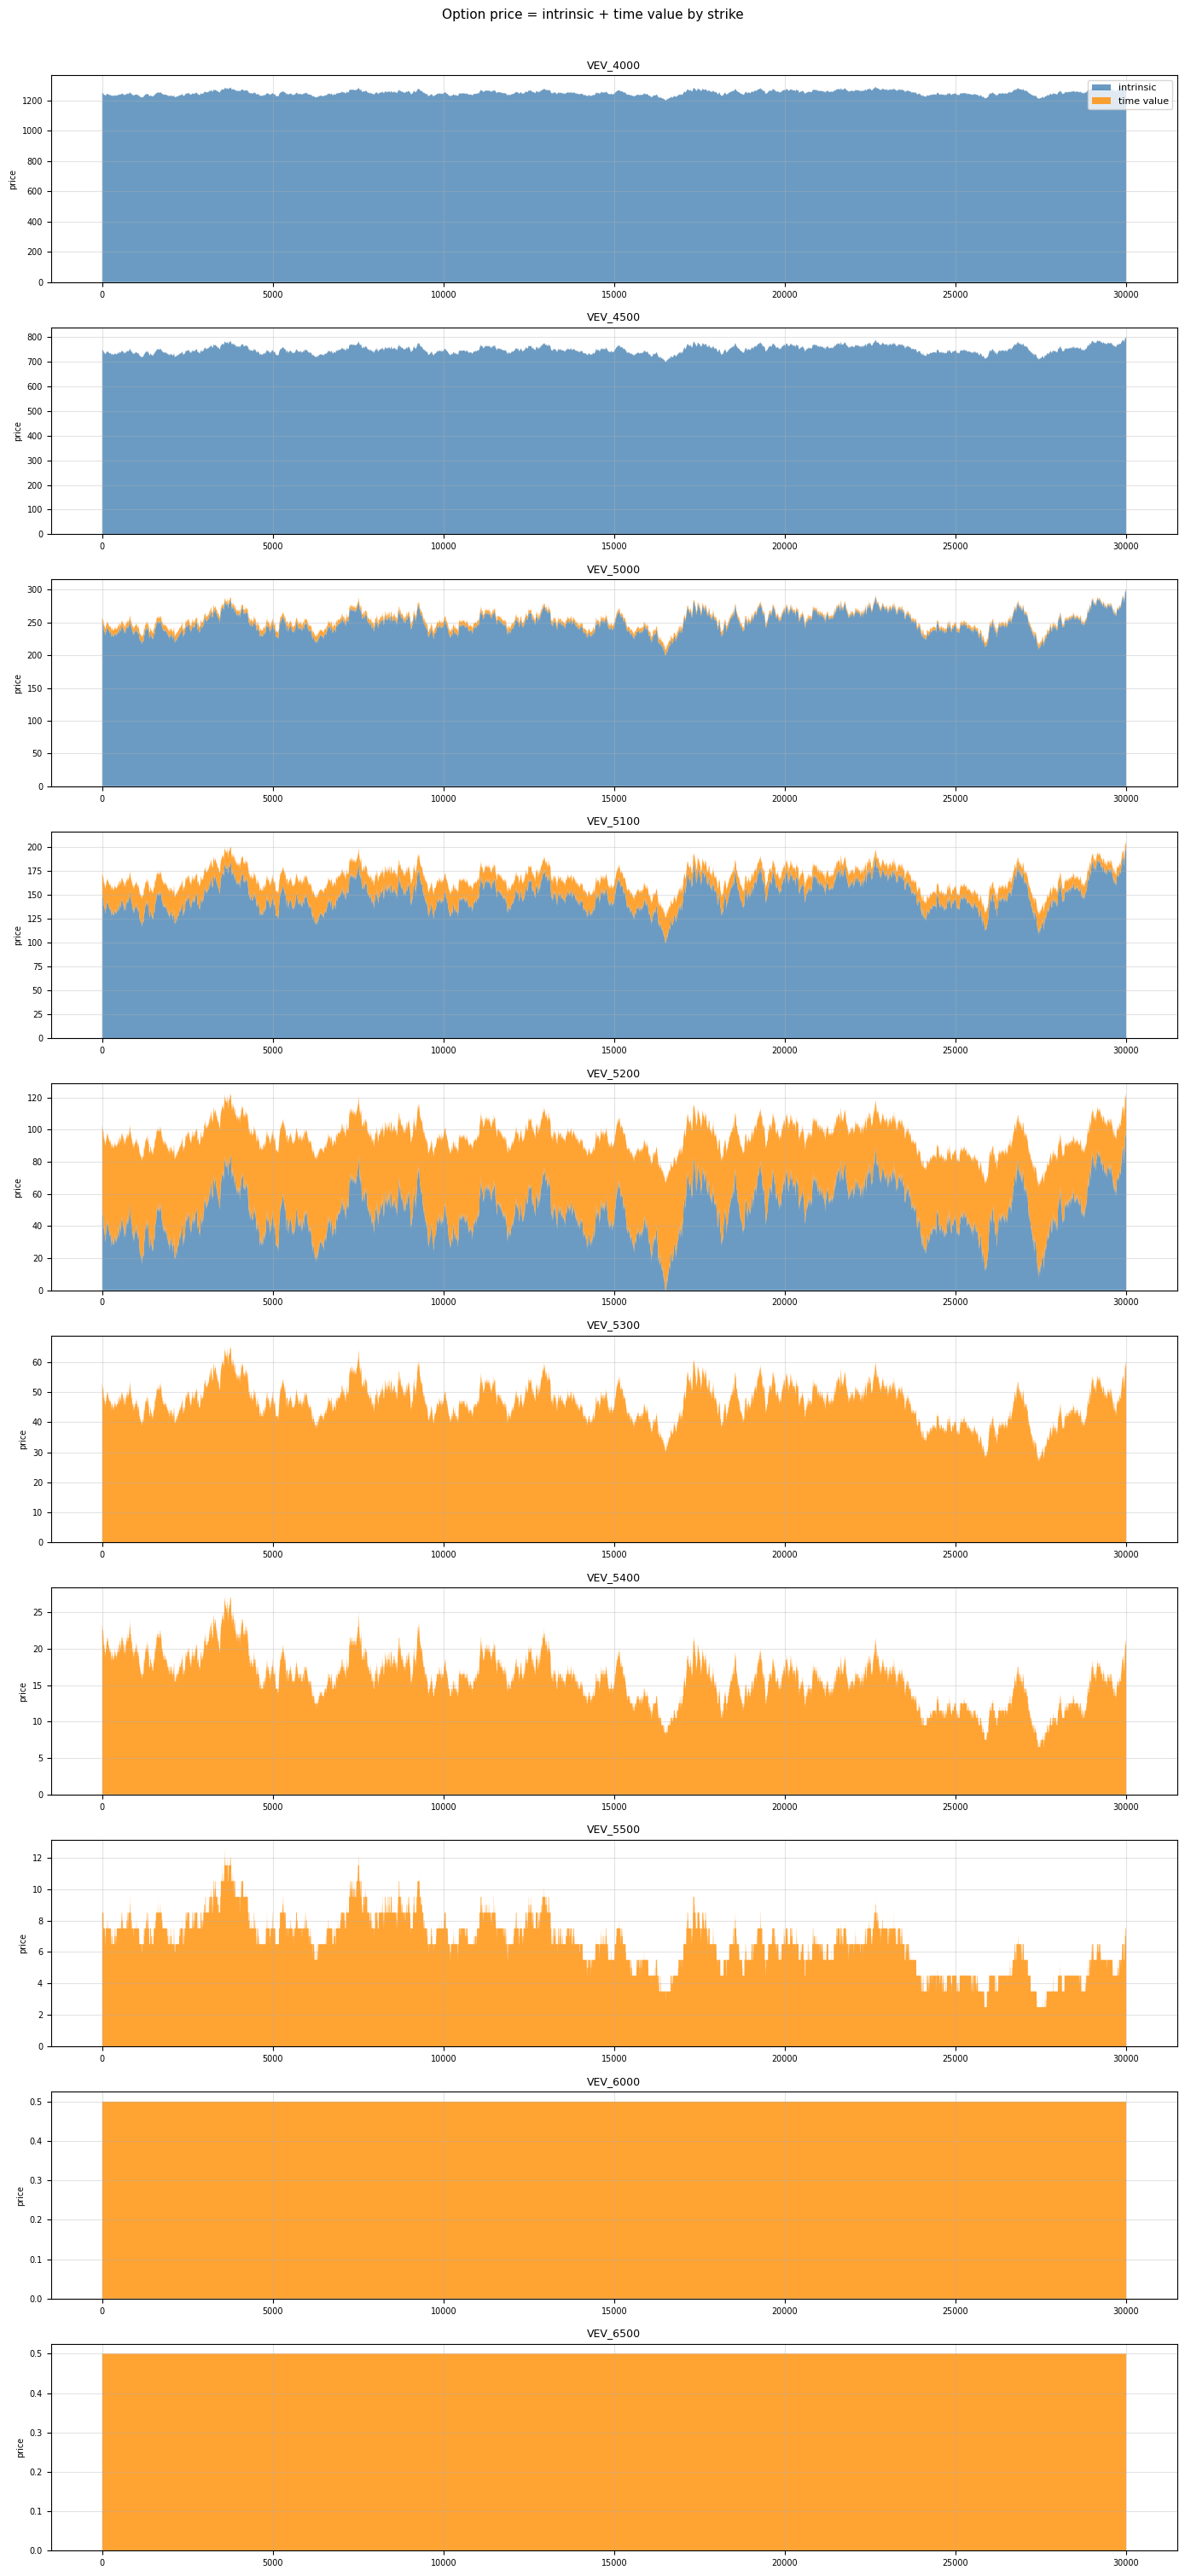

In [77]:
fig, axes = plt.subplots(len(STRIKES), 1, figsize=(14, 3*len(STRIKES)), sharex=False)
for i, k in enumerate(STRIKES):
    opt = prices[prices['product'] == f'VEV_{k}'].set_index(['day','timestamp'])['mid_price']
    df  = pd.DataFrame({'C': opt, 'S': S_idx}).dropna()
    df['intrinsic'] = (df['S'] - k).clip(lower=0)
    df['time_val']  = df['C'] - df['intrinsic']
    df = df.reset_index(); df['gx'] = range(len(df))
    axes[i].stackplot(df['gx'], df['intrinsic'], df['time_val'],
                      labels=['intrinsic','time value'],
                      colors=['steelblue','darkorange'], alpha=0.8)
    axes[i].set_title(f"VEV_{k}", fontsize=9)
    axes[i].set_ylabel("price", fontsize=7)
    axes[i].tick_params(labelsize=7)
    if i == 0: axes[i].legend(fontsize=8, loc='upper right')
plt.suptitle("Option price = intrinsic + time value by strike", y=1.005, fontsize=11)
plt.tight_layout(); plt.show()


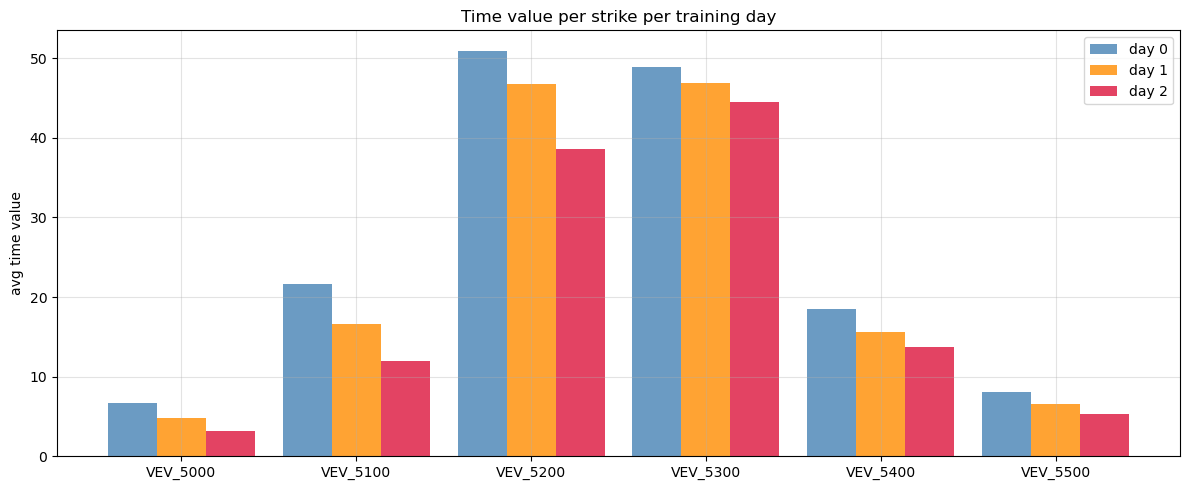

In [78]:
# Time value per strike per day — only training days
liquid = [k for k in STRIKES if k not in (4000, 4500, 6000, 6500)]
fig, ax = plt.subplots(figsize=(12, 5))
x     = np.arange(len(liquid))
width = 0.28
for di, day in enumerate(train_days):
    tv_vals = []
    for k in liquid:
        c_mean = prices[(prices['product']==f'VEV_{k}') & (prices['day']==day)]['mid_price'].mean()
        s_mean = prices[(prices['product']==UNDERLYING)  & (prices['day']==day)]['mid_price'].mean()
        tv_vals.append(max(c_mean - max(s_mean - k, 0), 0))
    ax.bar(x + di*width, tv_vals, width, label=f"day {day}",
           color=list(DAY_COLORS.values())[di], alpha=0.8)
ax.set_xticks(x + width); ax.set_xticklabels([f'VEV_{k}' for k in liquid])
ax.set_ylabel("avg time value"); ax.set_title("Time value per strike per training day")
ax.legend(); plt.tight_layout(); plt.show()


**Section 5 takeaways — Intrinsic Value & Time Value:**
- Stacked area: orange = time value (the "optionality premium"), blue = intrinsic (max(S-K, 0)).
- Deep ITM options (VEV_5000 and below): nearly all intrinsic, almost no time value. These move 1:1 with S.
- ATM options (VEV_5200, VEV_5300): time value is the dominant component. Most sensitive to volatility changes.
- Deep OTM (VEV_5500): almost entirely time value, but price is very small.
- Bar chart: time value decreases from day 0 to day 2, consistent with the observed IV drift downward across days.

## 6. Option Price vs Underlying Price

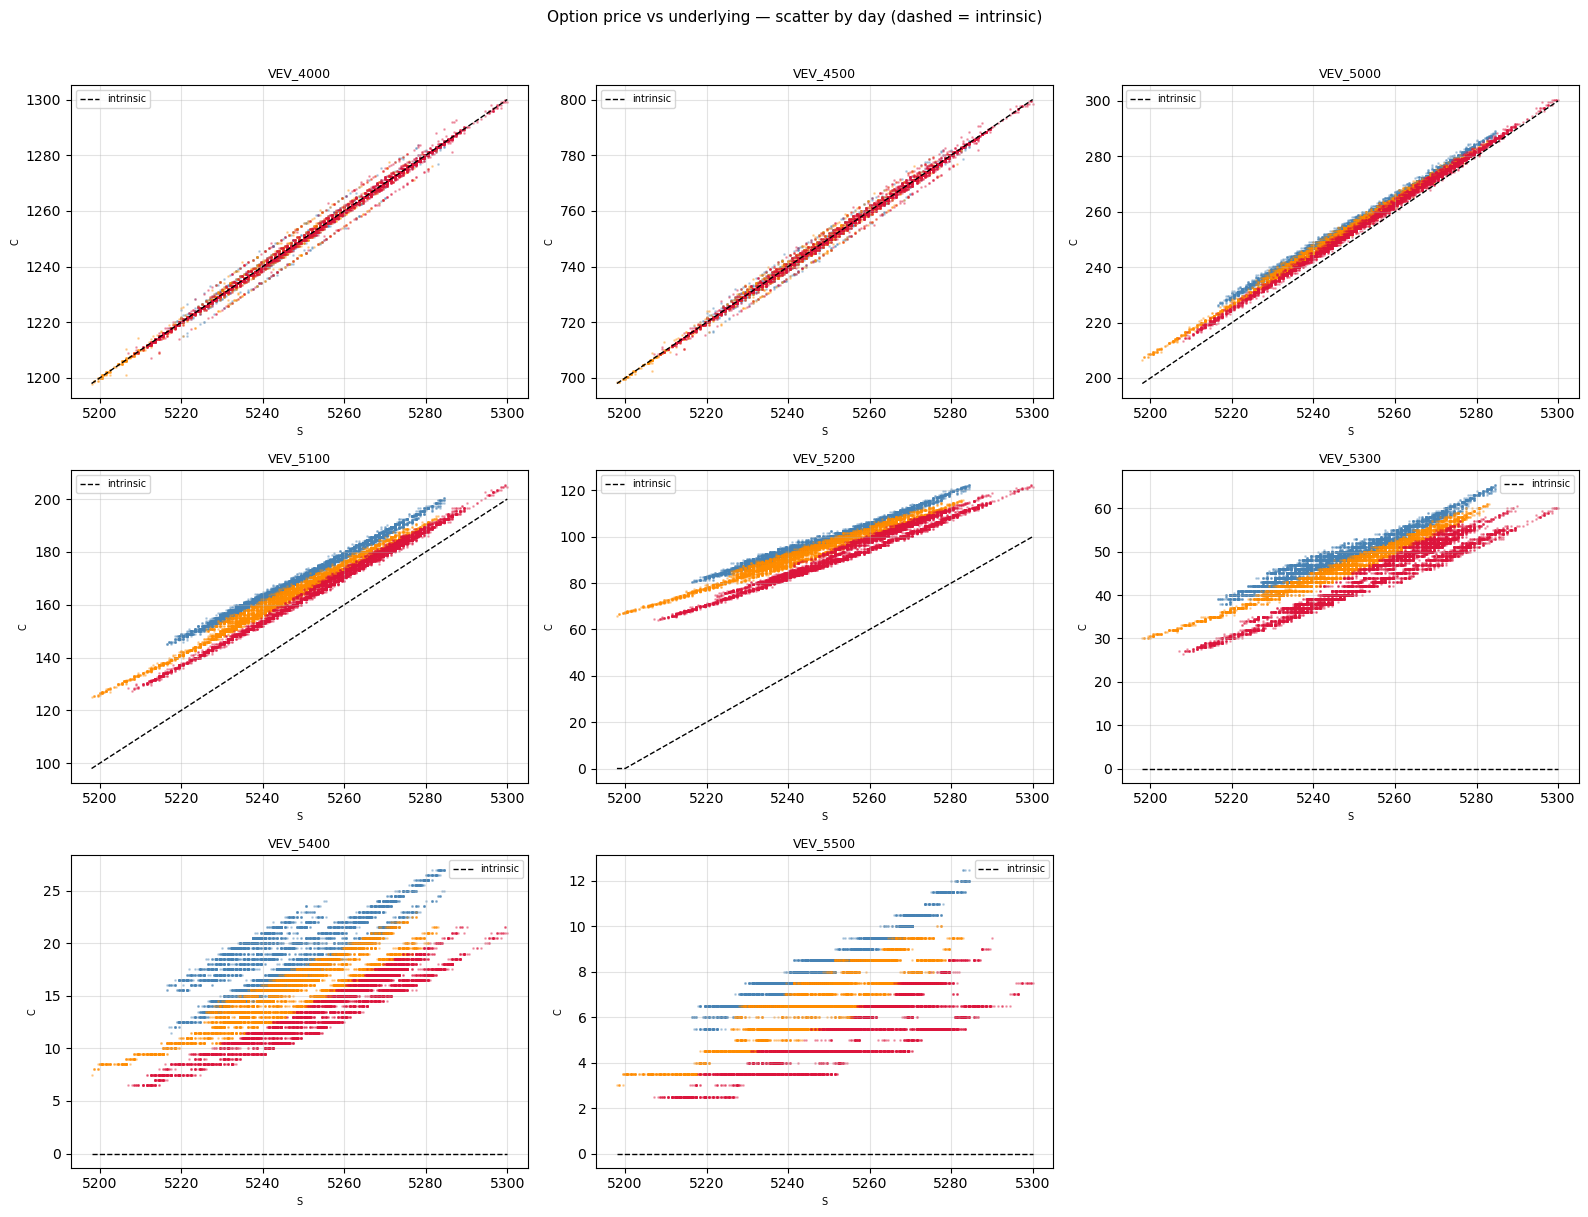

In [79]:
liquid = [k for k in STRIKES if k not in (6000, 6500)]
n_cols = 3; n_rows = math.ceil(len(liquid) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4*n_rows))
axes = axes.flatten()
for i, k in enumerate(liquid):
    opt = prices[prices['product'] == f'VEV_{k}'].set_index(['day','timestamp'])['mid_price']
    df  = pd.DataFrame({'C': opt, 'S': S_idx}).dropna()
    for day in train_days:
        mask = df.index.get_level_values('day') == day
        axes[i].scatter(df['S'][mask], df['C'][mask],
                        s=1, alpha=0.3, color=DAY_COLORS[day])
    s_range = np.linspace(df['S'].min(), df['S'].max(), 200)
    axes[i].plot(s_range, np.maximum(s_range - k, 0),
                 color='black', linewidth=1, linestyle='--', label='intrinsic')
    axes[i].set_title(f"VEV_{k}", fontsize=9)
    axes[i].set_xlabel("S", fontsize=7); axes[i].set_ylabel("C", fontsize=7)
    axes[i].legend(fontsize=7)
for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle("Option price vs underlying — scatter by day (dashed = intrinsic)", y=1.01, fontsize=11)
plt.tight_layout(); plt.show()


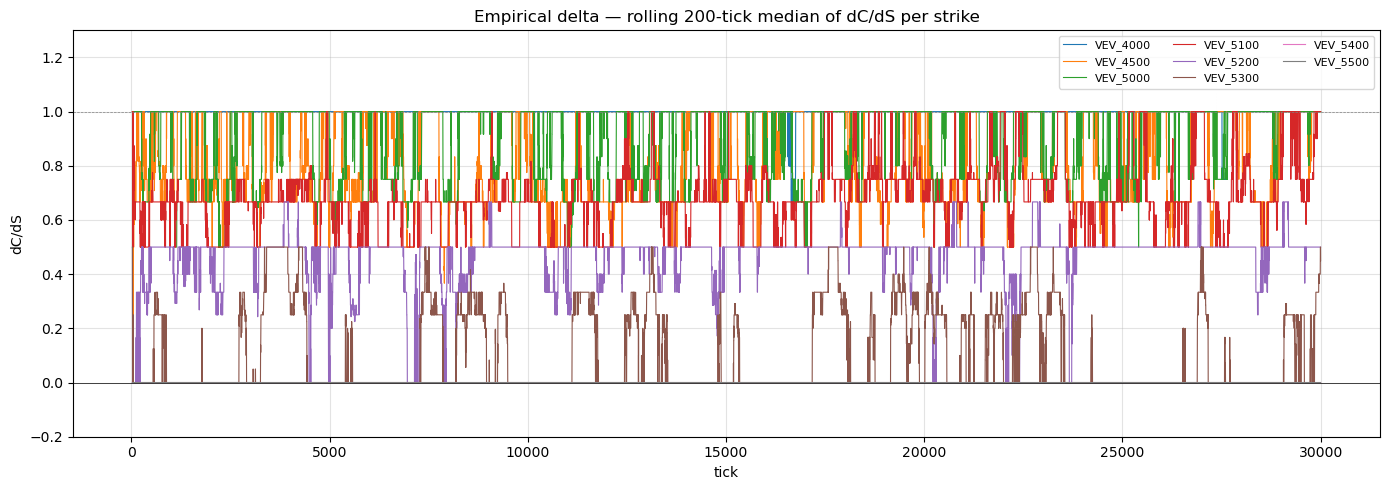

In [80]:
fig, ax = plt.subplots(figsize=(14, 5))
for k in liquid:
    opt = prices[prices['product'] == f'VEV_{k}'].set_index(['day','timestamp'])['mid_price']
    df  = pd.DataFrame({'C': opt, 'S': S_idx}).dropna().reset_index()
    dC  = df['C'].diff(); dS = df['S'].diff()
    ratio    = (dC / dS).replace([np.inf, -np.inf], np.nan)
    smoothed = ratio.rolling(200, min_periods=20).median()
    df['gx'] = range(len(df))
    ax.plot(df['gx'], smoothed, linewidth=0.8, label=f'VEV_{k}')
ax.axhline(0, color='black', linewidth=0.5)
ax.axhline(1, color='gray',  linewidth=0.5, linestyle='--')
ax.set_ylim(-0.2, 1.3)
ax.set_title("Empirical delta — rolling 200-tick median of dC/dS per strike")
ax.set_xlabel("tick"); ax.set_ylabel("dC/dS")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()


**Section 6 takeaways — Option Price vs Underlying:**
- Scatter: each dot is one tick. Color = day. Curve shape = convexity of the option.
- Deep ITM (VEV_5000, 5100): points cluster tightly along intrinsic — slope ~1, like holding the stock.
- ATM (VEV_5200, 5300): clear curvature above intrinsic. Slope ~0.5 at-the-money.
- OTM (VEV_5400, 5500): small prices, slope much less than 1.
- Empirical delta chart: rolling 200-tick median of dC/dS. Should converge to theoretical N(d1) for each strike. Flat lines = stable delta regimes. Spikes = noise from wide spreads or illiquidity.

## 7. Return Correlations — All Products

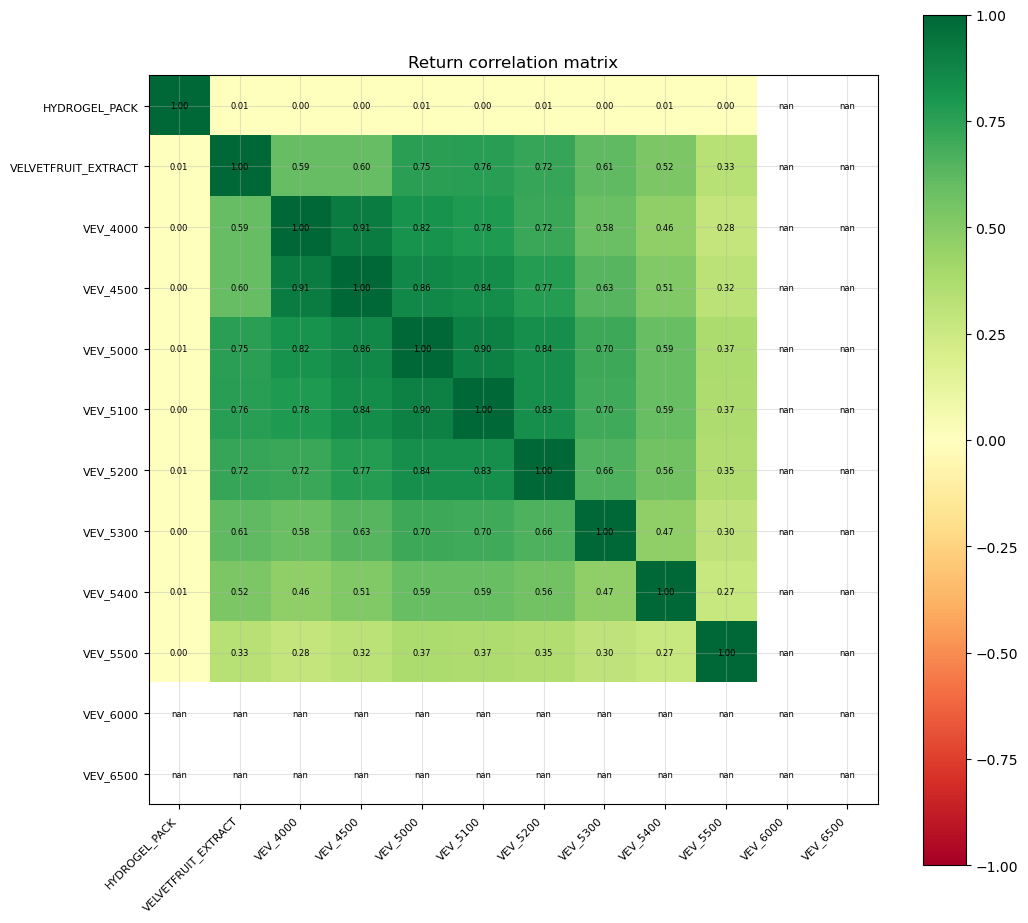

In [81]:
wide     = prices.pivot_table(index=['day','timestamp'], columns='product', values='mid_price')
ret_wide = wide.pct_change().dropna()
corr     = ret_wide.corr()
n = len(corr)
fig, ax = plt.subplots(figsize=(max(8, n*0.9), max(7, n*0.8)))
im = ax.imshow(corr, cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(corr.columns, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(n)); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha='center', va='center', fontsize=6)
plt.colorbar(im, ax=ax)
ax.set_title("Return correlation matrix")
plt.tight_layout(); plt.show()


**Section 7 takeaways — Return Correlations:**
- VEV options are highly correlated with each other and with VELVETFRUIT_EXTRACT (expected — all driven by the same S).
- Correlation among options increases as strikes get closer together.
- HYDROGEL_PACK shows near-zero correlation with all VEV products — treat it as a completely separate book.
- High inter-option correlation means mispricings in one strike often appear simultaneously across nearby strikes (vol surface moves as a unit). This can be exploited when one strike is mispriced vs others.

## 8. Implied Volatility

IV is computed by numerically inverting Black-Scholes: find σ such that BS(S, K, T=1.0, σ) = market price.
Raw values only — no smoothing, no signals.


In [82]:
def norm_cdf(x):
    a1,a2,a3,a4,a5 = 0.254829592,-0.284496736,1.421413741,-1.453152027,1.061405429
    p = 0.3275911; sign = 1 if x >= 0 else -1
    x = abs(x) / math.sqrt(2.0); t = 1.0 / (1.0 + p*x)
    y = 1.0 - (((((a5*t+a4)*t)+a3)*t+a2)*t+a1)*t*math.exp(-x*x)
    return 0.5*(1.0 + sign*y)

def bs_call(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return max(S - K, 0.0)
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    d2 = d1 - sigma*math.sqrt(T)
    return S*norm_cdf(d1) - K*norm_cdf(d2)

def implied_vol(mkt, S, K, T=1.0):
    if mkt <= max(S - K, 0.0) or S <= 0: return np.nan
    lo, hi = 1e-6, 5.0
    if bs_call(S, K, T, hi) < mkt: return np.nan
    for _ in range(100):
        mid = (lo + hi) / 2
        if bs_call(S, K, T, mid) < mkt: lo = mid
        else: hi = mid
        if hi - lo < 1e-6: return (lo + hi) / 2
    return (lo + hi) / 2

T_REF     = 1.0
iv_liquid = [k for k in STRIKES if k not in (4000, 4500, 6000, 6500)]
colors_iv = plt.cm.plasma(np.linspace(0.1, 0.9, len(iv_liquid)))


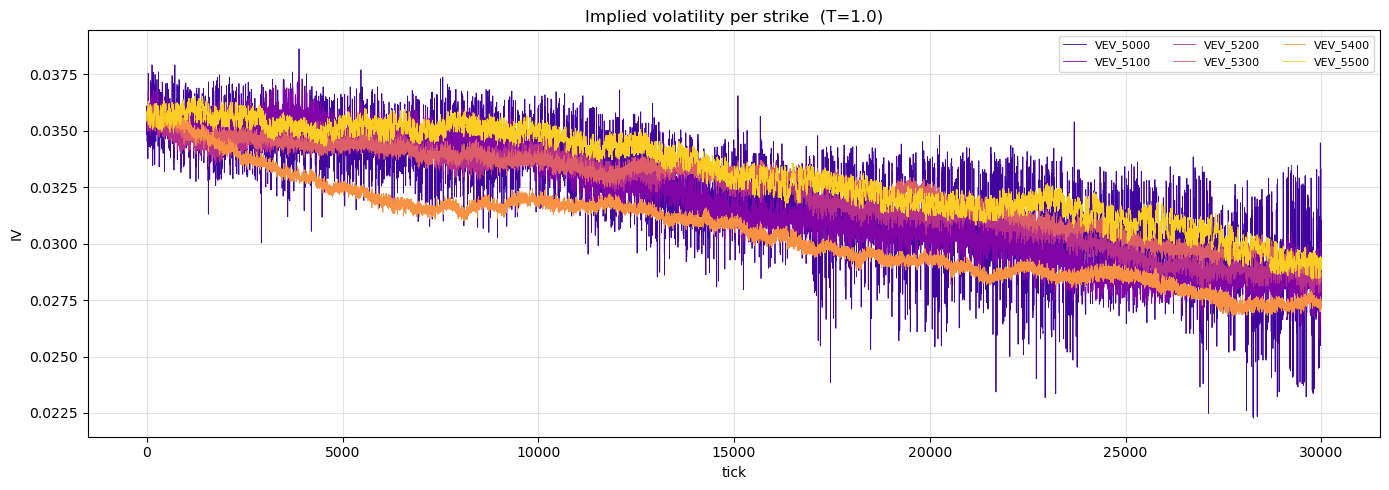

In [83]:
iv_data = {}
for k in iv_liquid:
    opt = prices[prices['product'] == f'VEV_{k}'].copy()              .sort_values(['day','timestamp']).reset_index(drop=True)
    opt = opt.join(S_idx.rename('S'), on=['day','timestamp'])
    opt['IV'] = [implied_vol(r['mid_price'], r['S'], k)
                 for _, r in opt.iterrows()]
    opt['gx'] = range(len(opt))
    iv_data[k] = opt

fig, ax = plt.subplots(figsize=(14, 5))
for i, k in enumerate(iv_liquid):
    df = iv_data[k]
    ax.plot(df['gx'], df['IV'], linewidth=0.6, color=colors_iv[i], label=f'VEV_{k}')
ax.set_title(f"Implied volatility per strike  (T={T_REF})")
ax.set_xlabel("tick"); ax.set_ylabel("IV")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()


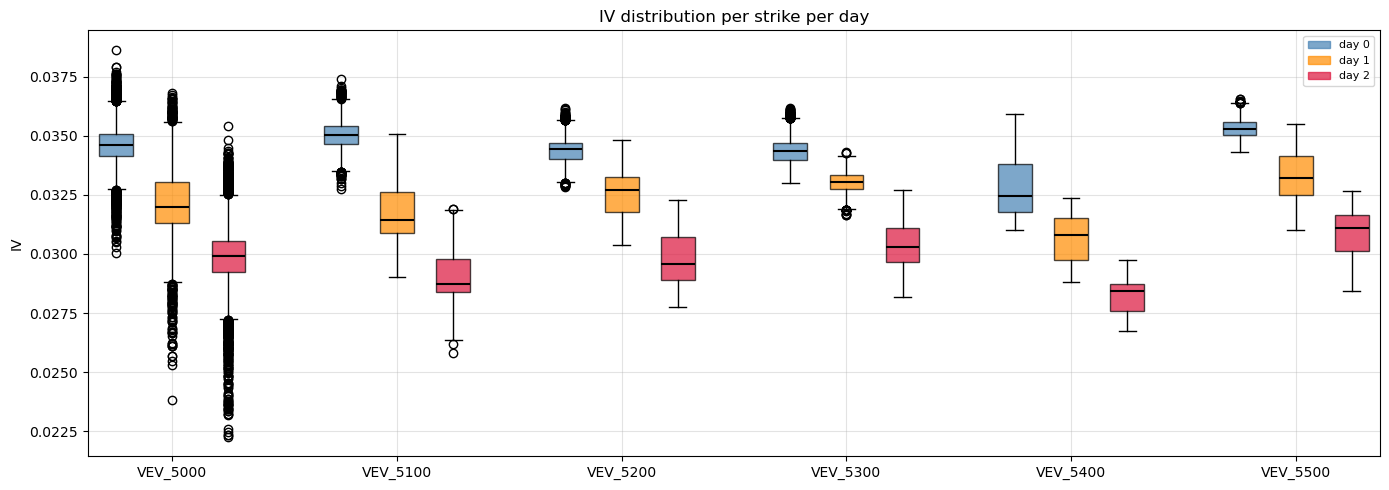

In [84]:
# IV box plots per strike per day
fig, ax = plt.subplots(figsize=(14, 5))
box_data, positions = [], []
for ki, k in enumerate(iv_liquid):
    for di, day in enumerate(train_days):
        iv_vals = iv_data[k][iv_data[k]['day'] == day]['IV'].dropna().values
        box_data.append(iv_vals)
        positions.append(ki * (len(train_days) + 1) + di)

bp = ax.boxplot(box_data, positions=positions, widths=0.6, patch_artist=True,
                medianprops=dict(color='black', linewidth=1.5))
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(list(DAY_COLORS.values())[i % len(train_days)])
    patch.set_alpha(0.7)
tick_pos = [ki*(len(train_days)+1) + (len(train_days)-1)/2 for ki in range(len(iv_liquid))]
ax.set_xticks(tick_pos); ax.set_xticklabels([f'VEV_{k}' for k in iv_liquid])
ax.set_title("IV distribution per strike per day"); ax.set_ylabel("IV")
handles = [plt.Rectangle((0,0),1,1, color=list(DAY_COLORS.values())[d], alpha=0.7)
           for d in range(len(train_days))]
ax.legend(handles, [f'day {d}' for d in train_days], fontsize=8)
plt.tight_layout(); plt.show()


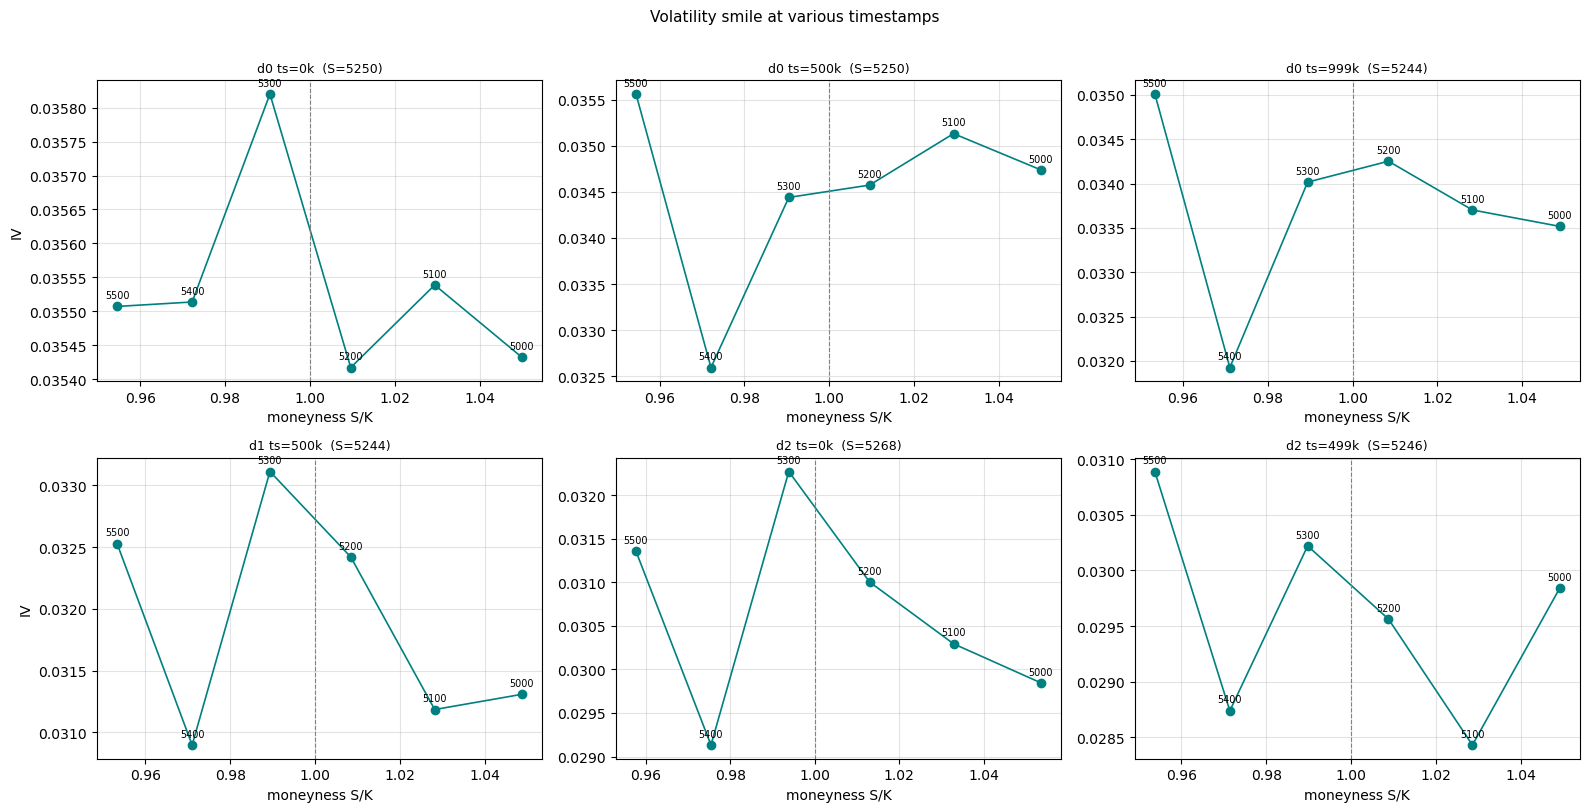

In [85]:
# Vol smile — all snapshots within training window
snapshots = [(0, 0), (0, 500000), (0, 999900),
             (1, 500000), (2, 0), (2, 499900)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for si, (day, ts) in enumerate(snapshots):
    S_arr = prices[(prices['product']==UNDERLYING) &
                   (prices['day']==day) &
                   (prices['timestamp']==ts)]['mid_price'].values
    if not len(S_arr): axes[si].set_title("no data"); continue
    S = S_arr[0]
    mn_vals, iv_vals, k_vals = [], [], []
    for k in iv_liquid:
        c_arr = prices[(prices['product']==f'VEV_{k}') &
                       (prices['day']==day) &
                       (prices['timestamp']==ts)]['mid_price'].values
        if len(c_arr):
            v = implied_vol(c_arr[0], S, k)
            if not np.isnan(v):
                mn_vals.append(S/k); iv_vals.append(v); k_vals.append(k)
    if mn_vals:
        axes[si].plot(mn_vals, iv_vals, 'o-', color='teal', linewidth=1.2, markersize=6)
        for kk, mn, iv_v in zip(k_vals, mn_vals, iv_vals):
            axes[si].annotate(str(kk), (mn, iv_v),
                              textcoords='offset points', xytext=(0,6), fontsize=7, ha='center')
    axes[si].axvline(1.0, color='gray', linestyle='--', linewidth=0.8)
    axes[si].set_title(f"d{day} ts={ts//1000}k  (S={S:.0f})", fontsize=9)
    axes[si].set_xlabel("moneyness S/K")
    axes[si].set_ylabel("IV") if si % 3 == 0 else None
plt.suptitle("Volatility smile at various timestamps", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()


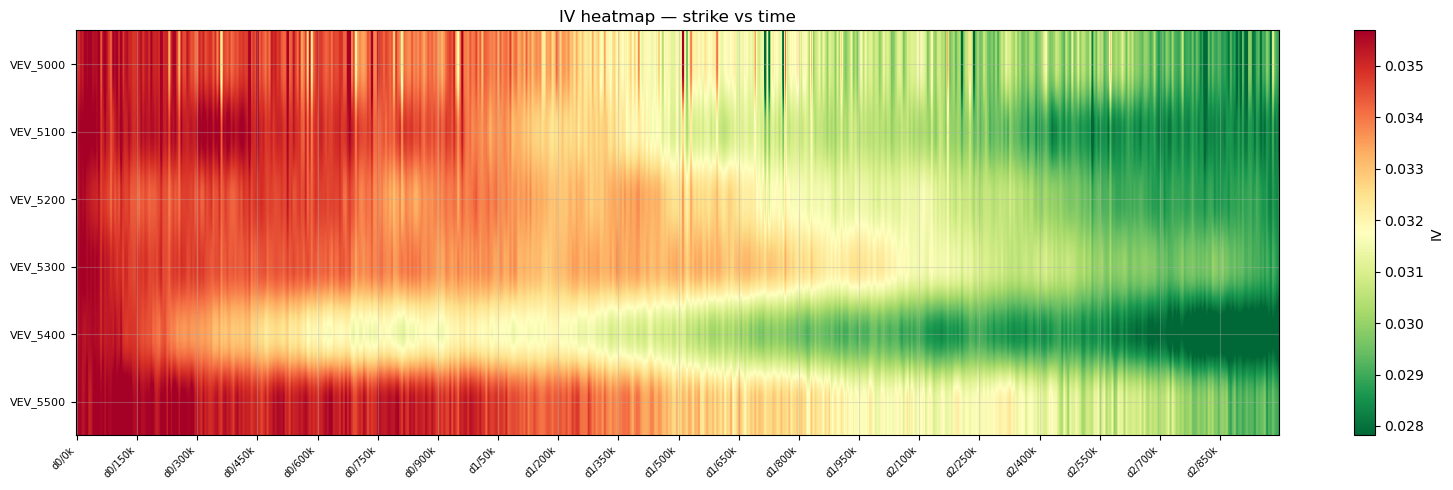

In [86]:
# IV heatmap — strike (y) vs tick (x)
from matplotlib.colors import Normalize
step     = 50
n_ticks  = len(iv_data[iv_liquid[0]])
tick_idx = list(range(0, n_ticks, step))
surface  = np.full((len(iv_liquid), len(tick_idx)), np.nan)
for ri, k in enumerate(iv_liquid):
    iv_arr = iv_data[k]['IV'].values
    for ci, ti in enumerate(tick_idx):
        if ti < len(iv_arr): surface[ri, ci] = iv_arr[ti]

fig, ax = plt.subplots(figsize=(16, 5))
im = ax.imshow(surface, aspect='auto', cmap='RdYlGn_r',
               norm=Normalize(vmin=np.nanpercentile(surface, 2),
                              vmax=np.nanpercentile(surface, 98)))
ax.set_yticks(range(len(iv_liquid)))
ax.set_yticklabels([f'VEV_{k}' for k in iv_liquid], fontsize=8)
n_xt = 20
xtick_pos  = [int(i * len(tick_idx) / n_xt) for i in range(n_xt)]
xtick_labs = []
for tp in xtick_pos:
    ti  = tick_idx[min(tp, len(tick_idx)-1)]
    row = iv_data[iv_liquid[0]].iloc[min(ti, n_ticks-1)]
    xtick_labs.append(f"d{int(row['day'])}/{int(row['timestamp'])//1000}k")
ax.set_xticks(xtick_pos)
ax.set_xticklabels(xtick_labs, rotation=45, ha='right', fontsize=7)
plt.colorbar(im, ax=ax, label="IV")
ax.set_title("IV heatmap — strike vs time")
plt.tight_layout(); plt.show()


**Section 8 takeaways — Implied Volatility:**
- IV is the market's implied annualized volatility backing out of the option price via Black-Scholes (T=1.0 chosen to flatten the vol surface).
- IV is roughly constant across strikes at ~0.032 — a flat vol surface. This means BS with a single sigma per day describes the market well.
- IV decreases across days: ~0.034 (day 0) -> ~0.032 (day 1) -> ~0.030 (day 2). Systematic downward drift.
- Box plots: each day's IV range is tight within a strike, but shifts down day-over-day. Outliers signal noise or illiquidity at that tick.
- Vol smile: at any given snapshot, IV is nearly flat across moneyness (no skew or smile). A convex smile would indicate the market prices tail risk; flat means pricing is simple.
- Heatmap: green = low IV, red = high IV. Horizontal bands = IV shifts together across all strikes at the same time (vol regime moves). Vertical streaks would indicate individual strike mispricings.

## 8b. T Calibration — Testing Different Time-to-Expiry Conventions

Prosperity says TTE = 5 days at start of round 3, decreasing by 1 per day.
Within each day, T also decays as timestamp goes 0 → 999900.

Dynamic T formula: `TTE_days = (5 - day) - timestamp / 1_000_000`

Candidates tested:
- `T=1.0` — notebook default (arbitrary unit)
- `T=5.0` — raw days, fixed at round start (no intraday decay)
- `T=5/365` — annualized years, fixed at round start
- `T=dynamic_days` — `(5-day) - ts/1e6` (days, decays intraday)
- `T=dynamic_years` — same but divided by 365

The "right" T produces the flattest, most stable IV smile across strikes and days.

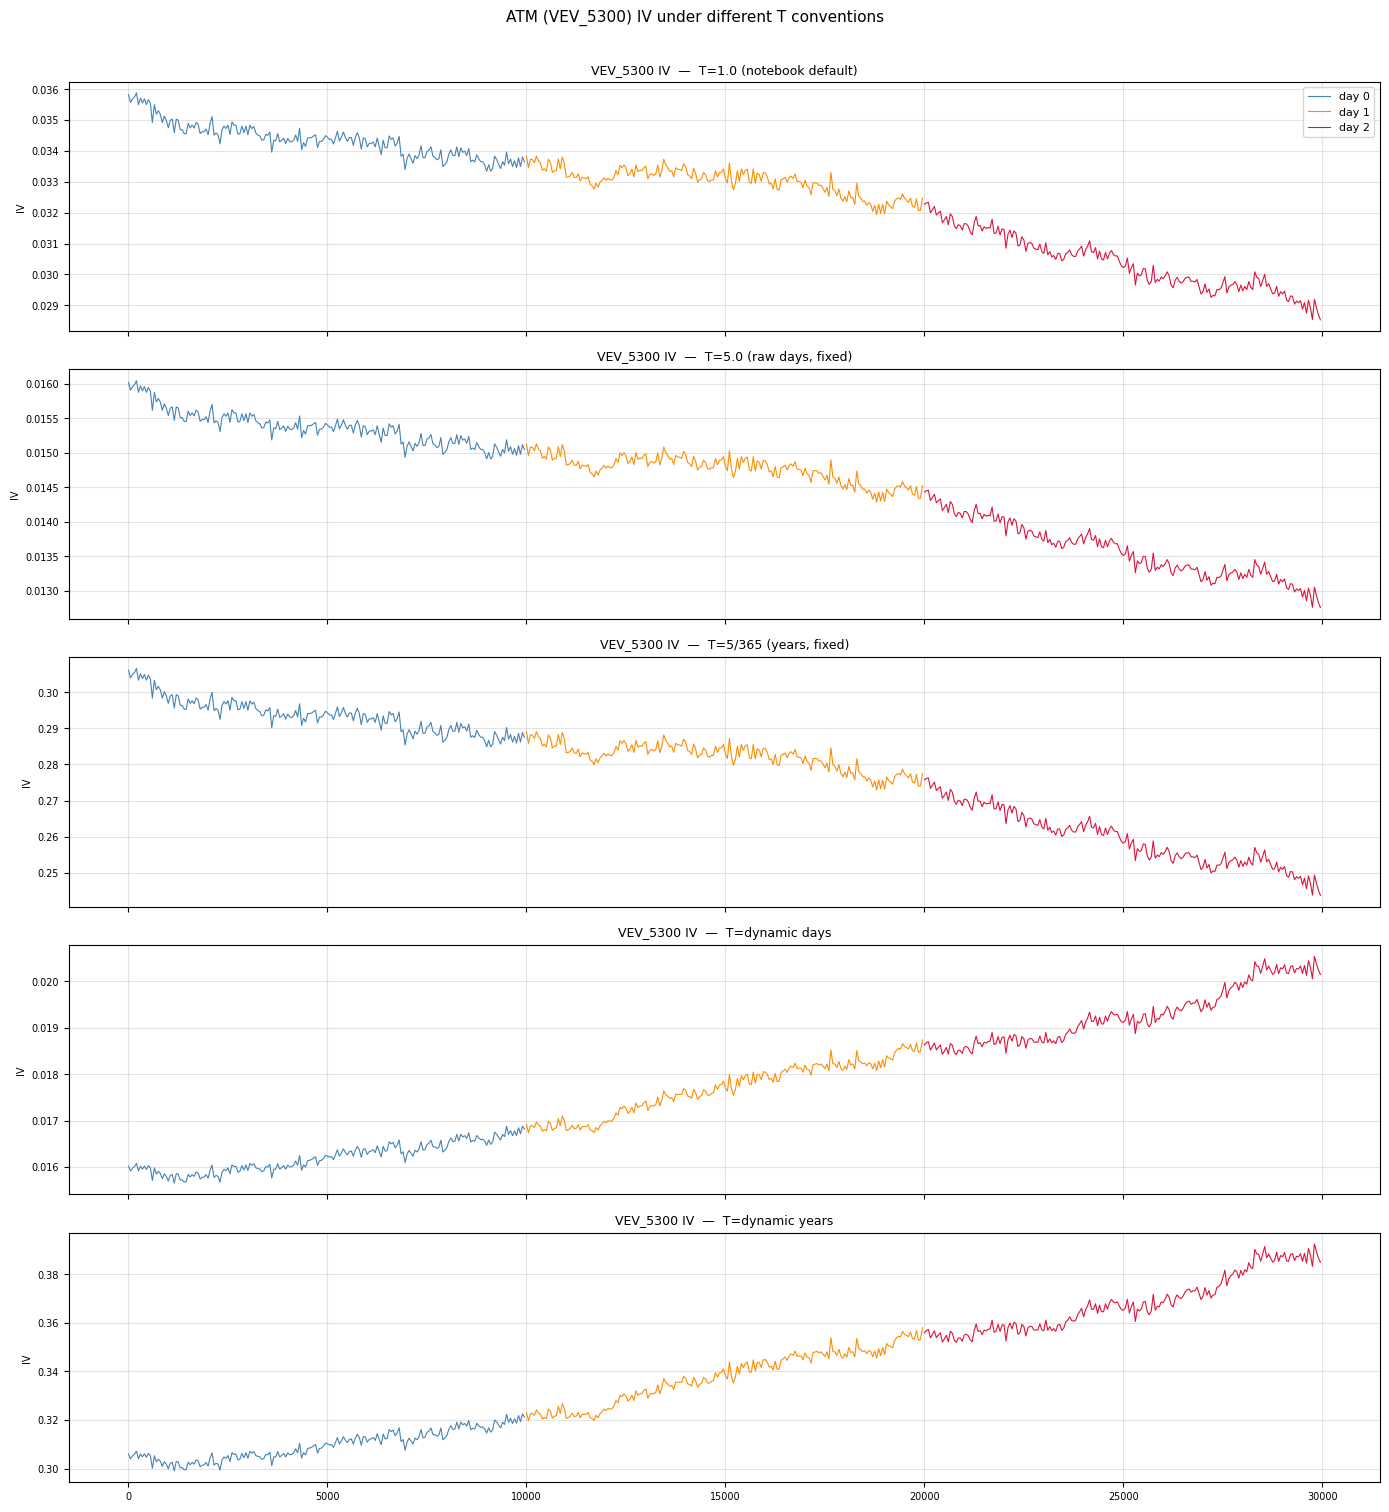

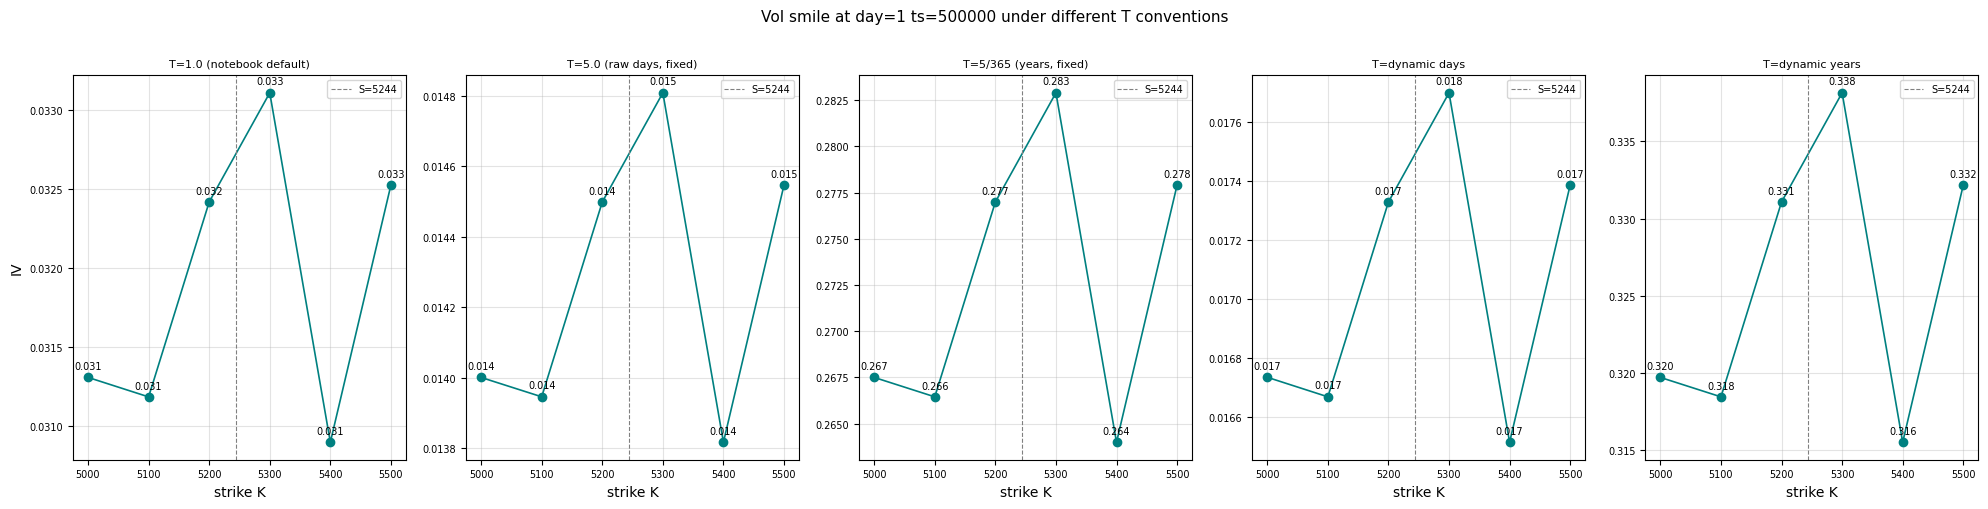


IV stability for VEV_5300 (lower std = more stable):
T convention                           mean IV     std IV
---------------------------------------------------------
T=1.0 (notebook default)               0.03259    0.00178
T=5.0 (raw days, fixed)                0.01457    0.00080
T=5/365 (years, fixed)                 0.27845    0.01523
T=dynamic days                         0.01773    0.00135
T=dynamic years                        0.33871    0.02574


In [87]:

# ── T candidates ──────────────────────────────────────────────────────────────
T_CANDIDATES = {
    "T=1.0 (notebook default)":  lambda day, ts: 1.0,
    "T=5.0 (raw days, fixed)":   lambda day, ts: 5.0,
    "T=5/365 (years, fixed)":    lambda day, ts: 5 / 365,
    "T=dynamic days":            lambda day, ts: (5 - day) - ts / 1_000_000,
    "T=dynamic years":           lambda day, ts: ((5 - day) - ts / 1_000_000) / 365,
}

# Sample every 50th tick to keep it fast
SAMPLE = 50
atm_strike = 5300  # closest liquid strike to S~5250

# ── Plot 1: IV time series for ATM strike across all T candidates ─────────────
fig, axes = plt.subplots(len(T_CANDIDATES), 1, figsize=(14, 3 * len(T_CANDIDATES)), sharex=True)
for ai, (label, T_fn) in enumerate(T_CANDIDATES.items()):
    opt = iv_data[atm_strike].iloc[::SAMPLE].copy()
    opt['T_val'] = [T_fn(r['day'], r['timestamp']) for _, r in opt.iterrows()]
    opt['IV_t']  = [implied_vol(r['mid_price'], r['S'], atm_strike, max(r['T_val'], 1e-6))
                    if pd.notna(r['S']) and r['T_val'] > 0 else np.nan
                    for _, r in opt.iterrows()]
    for day in train_days:
        seg = opt[opt['day'] == day]
        axes[ai].plot(seg['gx'], seg['IV_t'], color=DAY_COLORS[day],
                      linewidth=0.8, label=f'day {day}')
    axes[ai].set_title(f"VEV_{atm_strike} IV  —  {label}", fontsize=9)
    axes[ai].set_ylabel("IV", fontsize=7)
    axes[ai].tick_params(labelsize=7)
    if ai == 0:
        axes[ai].legend(fontsize=8)

plt.suptitle(f"ATM (VEV_{atm_strike}) IV under different T conventions", fontsize=11, y=1.005)
plt.tight_layout(); plt.show()

# ── Plot 2: Vol smile at fixed snapshot for each T candidate ──────────────────
snapshot_day, snapshot_ts = 1, 500000
S_snap = prices[(prices['product'] == UNDERLYING) &
                (prices['day'] == snapshot_day) &
                (prices['timestamp'] == snapshot_ts)]['mid_price'].values
S_snap = S_snap[0] if len(S_snap) else 5250.0

fig, axes = plt.subplots(1, len(T_CANDIDATES), figsize=(4 * len(T_CANDIDATES), 5))
for ai, (label, T_fn) in enumerate(T_CANDIDATES.items()):
    T_val = max(T_fn(snapshot_day, snapshot_ts), 1e-6)
    ivs = []
    for k in iv_liquid:
        c_arr = prices[(prices['product'] == f'VEV_{k}') &
                       (prices['day'] == snapshot_day) &
                       (prices['timestamp'] == snapshot_ts)]['mid_price'].values
        if len(c_arr):
            v = implied_vol(c_arr[0], S_snap, k, T_val)
            ivs.append((k, v))
    ks   = [x[0] for x in ivs if not np.isnan(x[1])]
    vals = [x[1] for x in ivs if not np.isnan(x[1])]
    axes[ai].plot(ks, vals, 'o-', linewidth=1.2, markersize=6, color='teal')
    for k, v in zip(ks, vals):
        axes[ai].annotate(f"{v:.3f}", (k, v), textcoords='offset points',
                          xytext=(0, 6), fontsize=7, ha='center')
    axes[ai].axvline(S_snap, color='gray', linestyle='--', linewidth=0.8, label=f'S={S_snap:.0f}')
    axes[ai].set_title(label, fontsize=8)
    axes[ai].set_xlabel("strike K")
    axes[ai].set_ylabel("IV") if ai == 0 else None
    axes[ai].legend(fontsize=7)
    axes[ai].tick_params(labelsize=7)

plt.suptitle(f"Vol smile at day={snapshot_day} ts={snapshot_ts} under different T conventions", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

# ── Print IV std per T (lower std = more stable IV = better T) ────────────────
print(f"\nIV stability for VEV_{atm_strike} (lower std = more stable):")
print(f"{'T convention':<35} {'mean IV':>10} {'std IV':>10}")
print("-" * 57)
for label, T_fn in T_CANDIDATES.items():
    opt = iv_data[atm_strike].copy()
    opt['T_val'] = [T_fn(r['day'], r['timestamp']) for _, r in opt.iterrows()]
    opt['IV_t']  = [implied_vol(r['mid_price'], r['S'], atm_strike, max(r['T_val'], 1e-6))
                    if pd.notna(r['S']) and r['T_val'] > 1e-6 else np.nan
                    for _, r in opt.iterrows()]
    print(f"{label:<35} {opt['IV_t'].mean():>10.5f} {opt['IV_t'].std():>10.5f}")


## 8c. T=5.0 IV Stats per Liquid Strike
Recomputes IV for the three tradeable strikes using T=5.0 (most stable T from 8b). Prints SEED_IV, SEED_VAR, and EMA_ALPHA values for round3_model.py.


T=5.0 IV stats per liquid strike:
Strike      mean_IV     std_IV       var_IV   lag1_ACF  EMA_alpha
-----------------------------------------------------------------
VEV_5300     0.014575   0.000797     6.35e-07     0.9934     0.0066
VEV_5400     0.013674   0.000961     9.23e-07     0.9969     0.0031
VEV_5500     0.014825   0.000894     7.99e-07     0.9943     0.0057


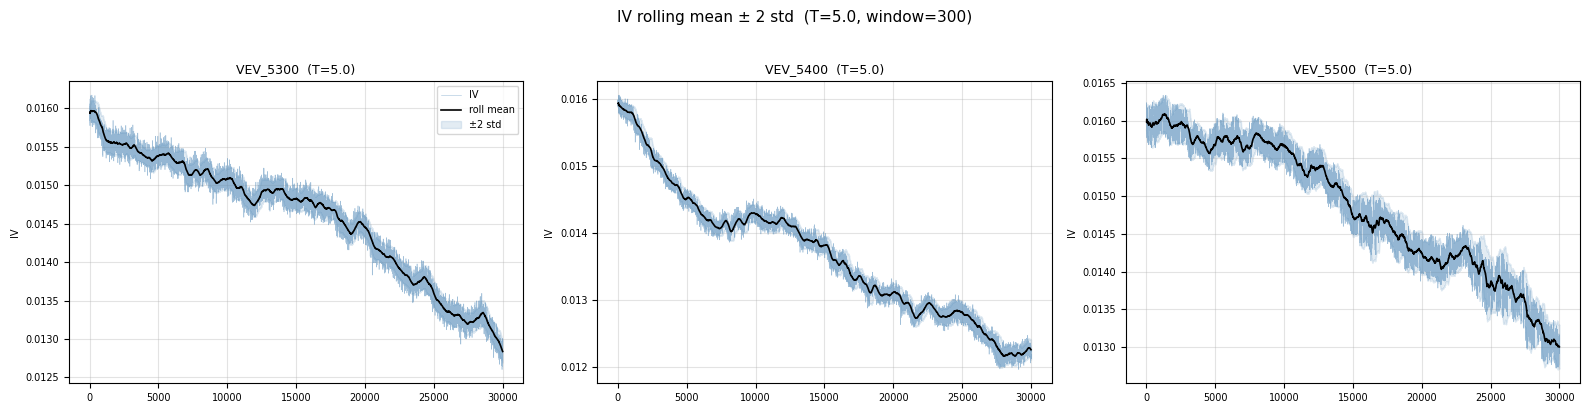

In [88]:
## 8c. T=5.0 IV stats per liquid strike — calibration values for round3_model.py
# Run this after section 8 (iv_data must already be built with T_REF=1.0).
# Recomputes IV with T=5.0 for the three liquid strikes and prints SEED_IV / SEED_VAR / EMA_ALPHA.

T5 = 5.0
liquid_cal = [5300, 5400, 5500]

iv_data_t5 = {}
for k in liquid_cal:
    opt = prices[prices['product'] == f'VEV_{k}'].copy().sort_values(['day','timestamp']).reset_index(drop=True)
    opt = opt.join(S_idx.rename('S'), on=['day','timestamp'])
    opt['IV'] = [implied_vol(r['mid_price'], r['S'], k, T5)
                 if pd.notna(r['S']) else np.nan
                 for _, r in opt.iterrows()]
    opt['gx'] = range(len(opt))
    iv_data_t5[k] = opt

print(f"T={T5} IV stats per liquid strike:")
print(f"{'Strike':<8} {'mean_IV':>10} {'std_IV':>10} {'var_IV':>12} {'lag1_ACF':>10} {'EMA_alpha':>10}")
print('-' * 65)
for k in liquid_cal:
    iv = iv_data_t5[k]['IV'].dropna()
    mean_iv = iv.mean()
    std_iv  = iv.std()
    var_iv  = iv.var()
    acf1    = iv.autocorr(1)
    alpha   = 1 - acf1
    print(f"VEV_{k}   {mean_iv:>10.6f} {std_iv:>10.6f} {var_iv:>12.2e} {acf1:>10.4f} {alpha:>10.4f}")

# Plot rolling IV with T=5.0
ROLL_WIN = 300
fig, axes = plt.subplots(1, len(liquid_cal), figsize=(16, 4))
for i, k in enumerate(liquid_cal):
    iv = iv_data_t5[k]['IV']
    gx = iv_data_t5[k]['gx']
    rm   = iv.rolling(ROLL_WIN, min_periods=30).mean()
    rstd = iv.rolling(ROLL_WIN, min_periods=30).std()
    axes[i].plot(gx, iv, color='steelblue', linewidth=0.4, alpha=0.5, label='IV')
    axes[i].plot(gx, rm, color='black', linewidth=1.2, label=f'roll mean')
    axes[i].fill_between(gx, rm - 2*rstd, rm + 2*rstd, alpha=0.15, color='steelblue', label='±2 std')
    axes[i].set_title(f'VEV_{k}  (T={T5})', fontsize=9)
    axes[i].set_ylabel('IV', fontsize=7)
    axes[i].tick_params(labelsize=7)
    if i == 0: axes[i].legend(fontsize=7)
plt.suptitle(f'IV rolling mean ± 2 std  (T={T5}, window={ROLL_WIN})', fontsize=11, y=1.02)
plt.tight_layout(); plt.show()


## 9. Greeks (Delta, Gamma, Theta)

In [89]:
def bs_delta(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return 1.0 if S > K else 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return norm_cdf(d1)

def bs_gamma(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return math.exp(-0.5*d1**2) / (S * sigma * math.sqrt(T) * math.sqrt(2*math.pi))

def bs_theta(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return -(S * math.exp(-0.5*d1**2) * sigma) / (2*math.sqrt(T)*math.sqrt(2*math.pi)) / 365


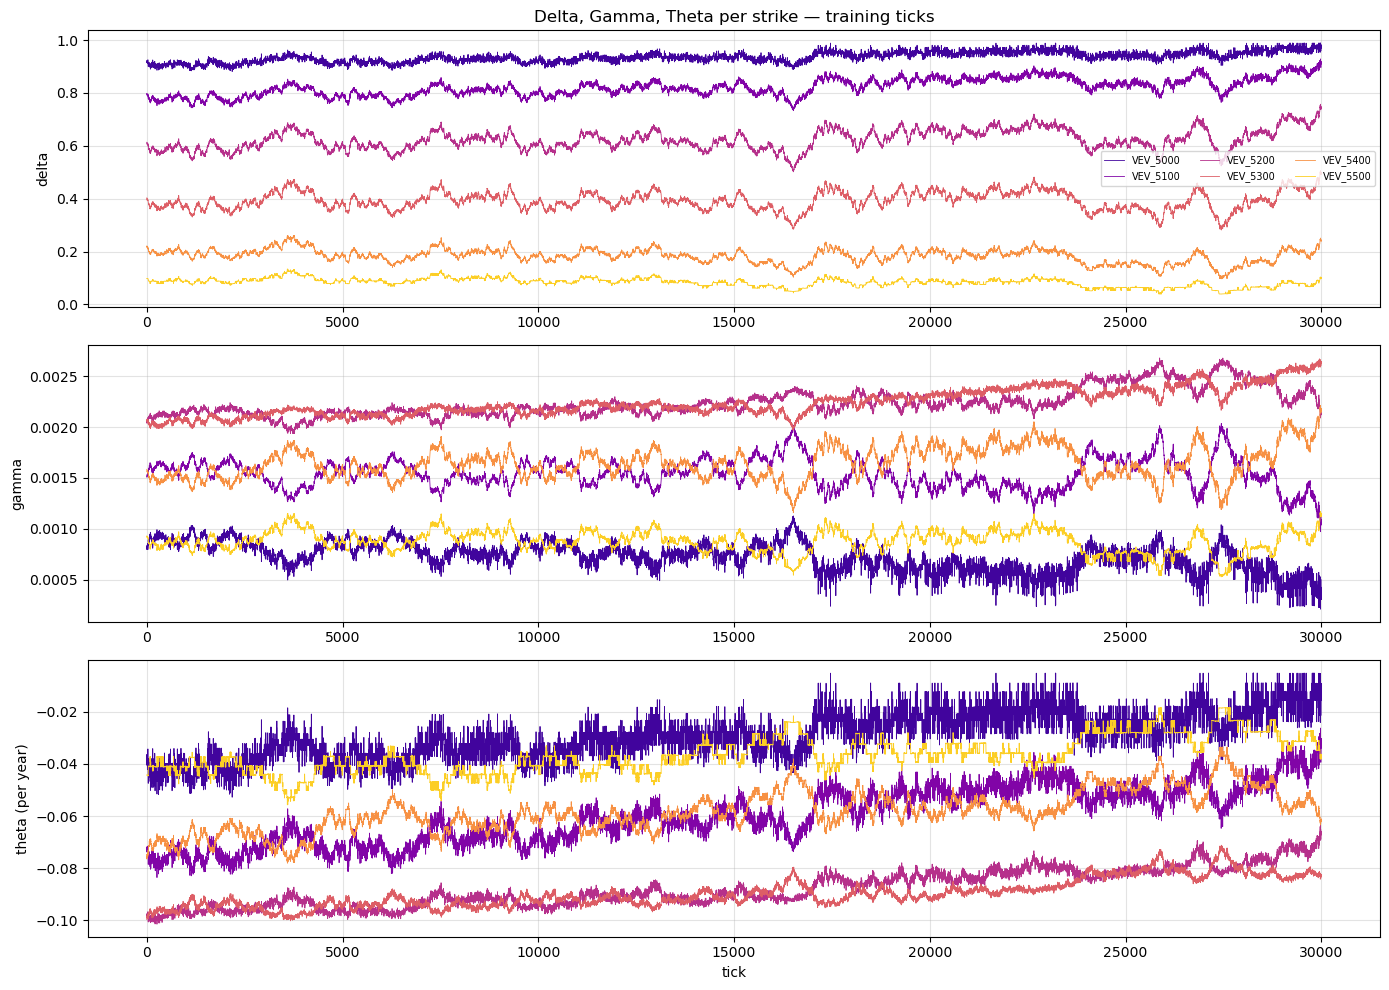

In [90]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
for i, k in enumerate(iv_liquid):
    df      = iv_data[k].copy()
    mean_iv = df['IV'].mean()
    df['iv_use'] = df['IV'].fillna(mean_iv)
    df['delta']  = [bs_delta(r['S'], k, T_REF, r['iv_use']) if pd.notna(r['S']) else np.nan for _, r in df.iterrows()]
    df['gamma']  = [bs_gamma(r['S'], k, T_REF, r['iv_use']) if pd.notna(r['S']) else np.nan for _, r in df.iterrows()]
    df['theta']  = [bs_theta(r['S'], k, T_REF, r['iv_use']) if pd.notna(r['S']) else np.nan for _, r in df.iterrows()]
    col = colors_iv[i]
    axes[0].plot(df['gx'], df['delta'], linewidth=0.6, color=col, label=f'VEV_{k}')
    axes[1].plot(df['gx'], df['gamma'], linewidth=0.6, color=col)
    axes[2].plot(df['gx'], df['theta'], linewidth=0.6, color=col)
axes[0].set_ylabel("delta"); axes[0].legend(fontsize=7, ncol=3)
axes[0].set_title("Delta, Gamma, Theta per strike — training ticks")
axes[1].set_ylabel("gamma")
axes[2].set_ylabel("theta (per year)"); axes[2].set_xlabel("tick")
plt.tight_layout(); plt.show()

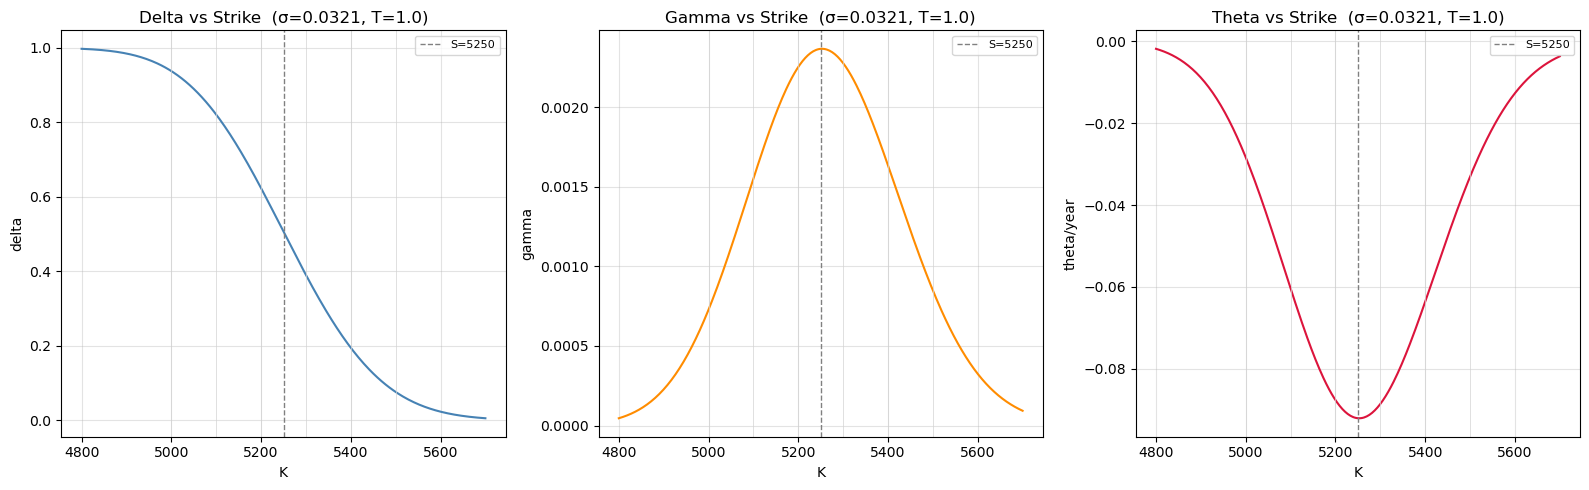

In [91]:
S_mean  = prices[prices['product']==UNDERLYING]['mid_price'].mean()
iv_flat = np.mean([iv_data[k]['IV'].mean() for k in iv_liquid])
K_range = np.linspace(4800, 5700, 300)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].plot(K_range, [bs_delta(S_mean, k, T_REF, iv_flat) for k in K_range], linewidth=1.5, color='steelblue')
axes[1].plot(K_range, [bs_gamma(S_mean, k, T_REF, iv_flat) for k in K_range], linewidth=1.5, color='darkorange')
axes[2].plot(K_range, [bs_theta(S_mean, k, T_REF, iv_flat) for k in K_range], linewidth=1.5, color='crimson')
for ax, title, ylabel in zip(axes,
        ['Delta vs Strike', 'Gamma vs Strike', 'Theta vs Strike'],
        ['delta', 'gamma', 'theta/year']):
    ax.axvline(S_mean, color='gray', linestyle='--', linewidth=1, label=f'S={S_mean:.0f}')
    ax.set_title(f"{title}  (σ={iv_flat:.4f}, T={T_REF})"); ax.set_xlabel("K")
    ax.set_ylabel(ylabel); ax.legend(fontsize=8)
    for k in iv_liquid: ax.axvline(k, color='lightgray', linewidth=0.5)
plt.tight_layout(); plt.show()


**Section 9 takeaways — Greeks:**
- **Delta** (dC/dS): ranges 0 to 1. Deep ITM = ~1 (moves with stock). Deep OTM = ~0. ATM = ~0.5. Delta over time reflects S moving around relative to each K.
- **Gamma** (d^2C/dS^2): rate of change of delta. Peaks at ATM (K near S ~5250). High gamma = position value is sensitive to large moves. Low gamma = stable delta.
- **Theta** (time decay per year): always negative for long options. Larger magnitude for ATM options. Tells you how much value the option loses per unit time if S stays flat.
- Static plots (vs K at fixed S, IV): show the shape of each greek across the strike spectrum. Vertical gray lines = our liquid strikes. Use these to understand which strikes are most sensitive.

## 10. Trade Activity

In [92]:
vol_summary = (trades.groupby('symbol')['quantity']
               .agg(n_trades='count', total_vol='sum')
               .sort_values('total_vol', ascending=False))
print(vol_summary.to_string())


                     n_trades  total_vol
symbol                                  
VELVETFRUIT_EXTRACT      1372       8269
HYDROGEL_PACK            1010       4078
VEV_6000                  284       1002
VEV_6500                  284       1002
VEV_4000                  464        940
VEV_5500                  267        937
VEV_5400                  225        787
VEV_5300                  121        420
VEV_5200                   18         63
VEV_4500                    1          1
VEV_5000                    1          1
VEV_5100                    1          1


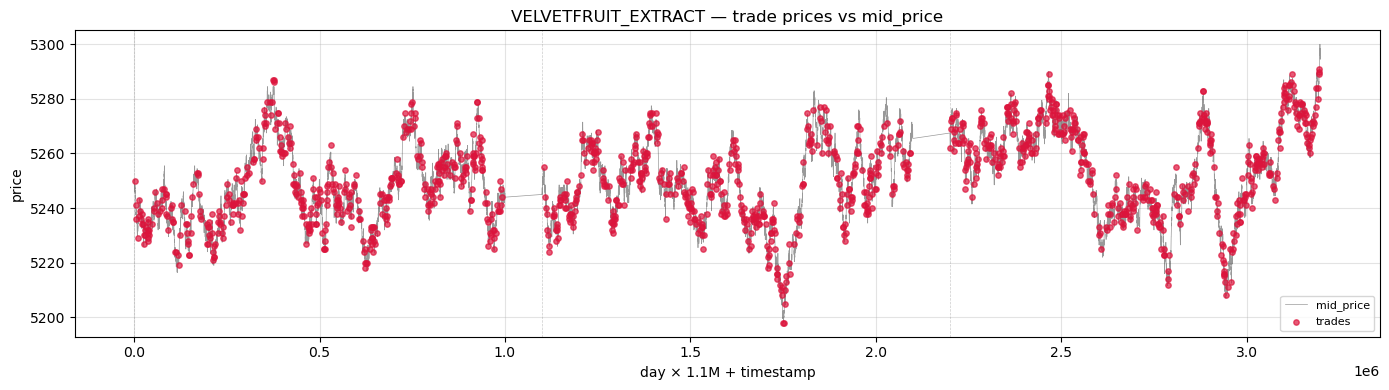

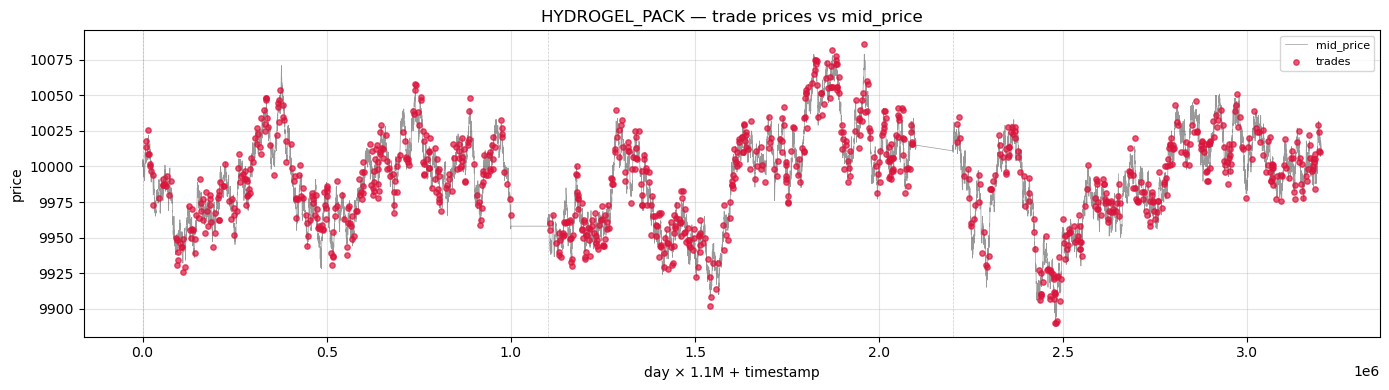

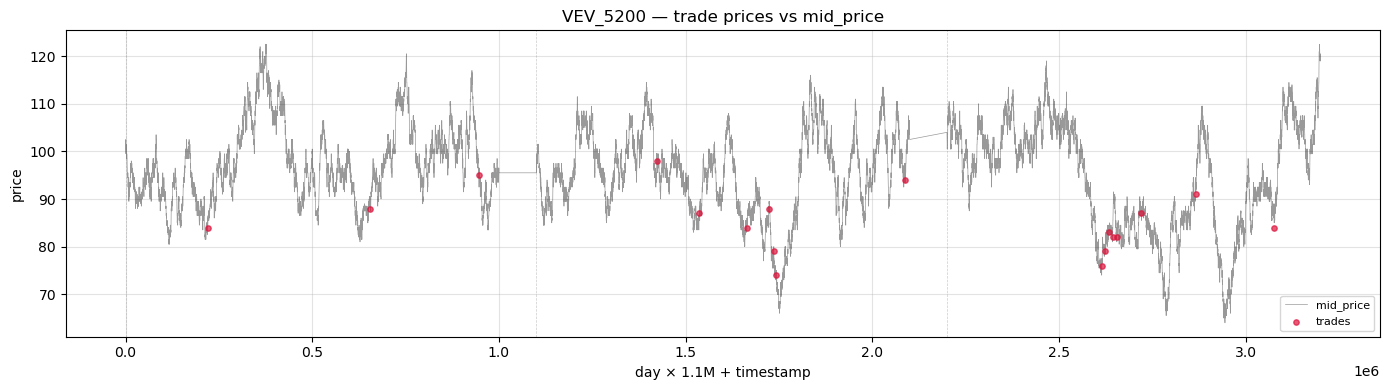

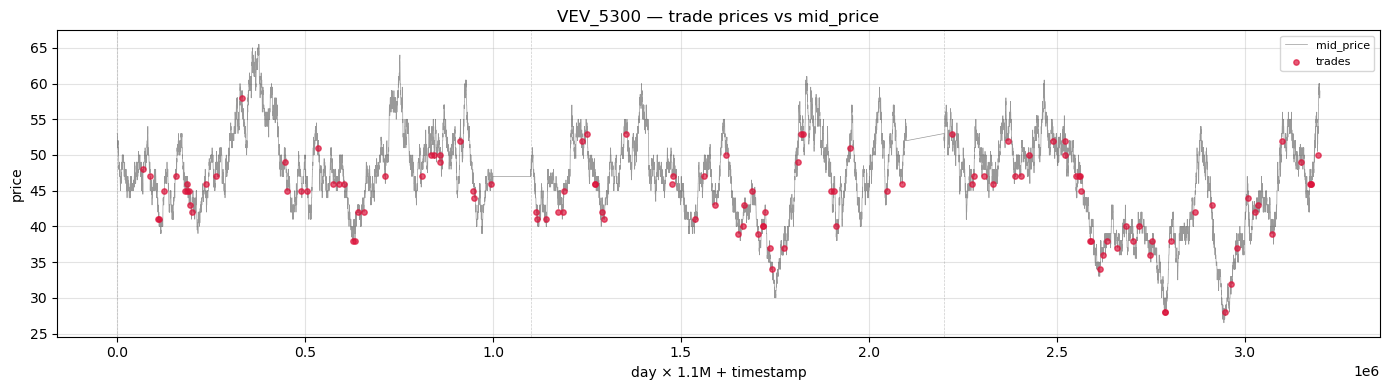

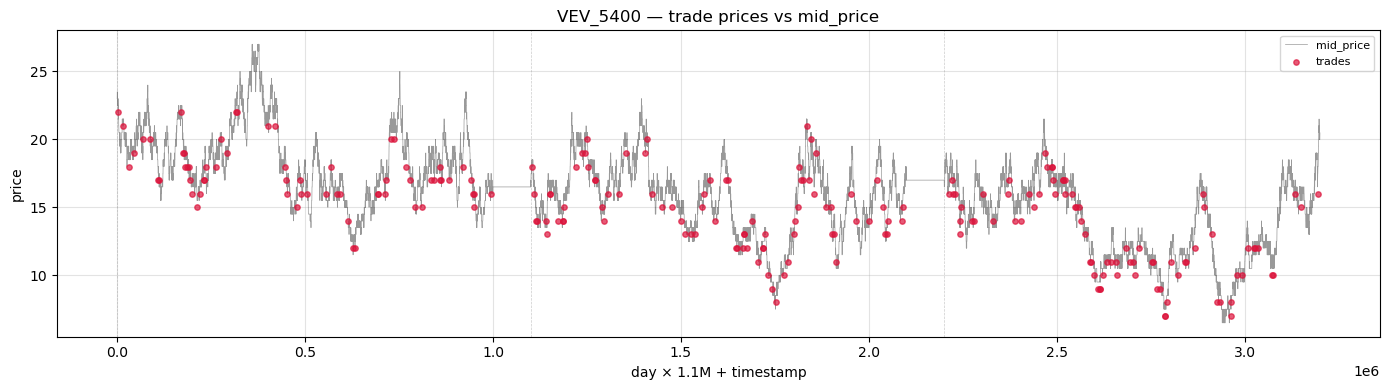

In [93]:
for prod in [UNDERLYING, HYDROGEL] + [f'VEV_{k}' for k in [5200, 5300, 5400]]:
    p = prices[prices['product'] == prod].copy()
    p['x'] = p['day'] * 1_100_000 + p['timestamp']
    t = trades[trades['symbol'] == prod].copy()
    t['x'] = t['day'] * 1_100_000 + t['timestamp']
    if t.empty: continue
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(p['x'], p['mid_price'], color='black', linewidth=0.5, alpha=0.4, label='mid_price')
    ax.scatter(t['x'], t['price'], s=15, color='crimson', zorder=3, alpha=0.7, label='trades')
    for day in train_days:
        ax.axvline(day * 1_100_000, color='gray', linestyle='--', linewidth=0.5, alpha=0.4)
    ax.set_title(f"{prod} — trade prices vs mid_price")
    ax.set_xlabel("day × 1.1M + timestamp"); ax.set_ylabel("price")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()


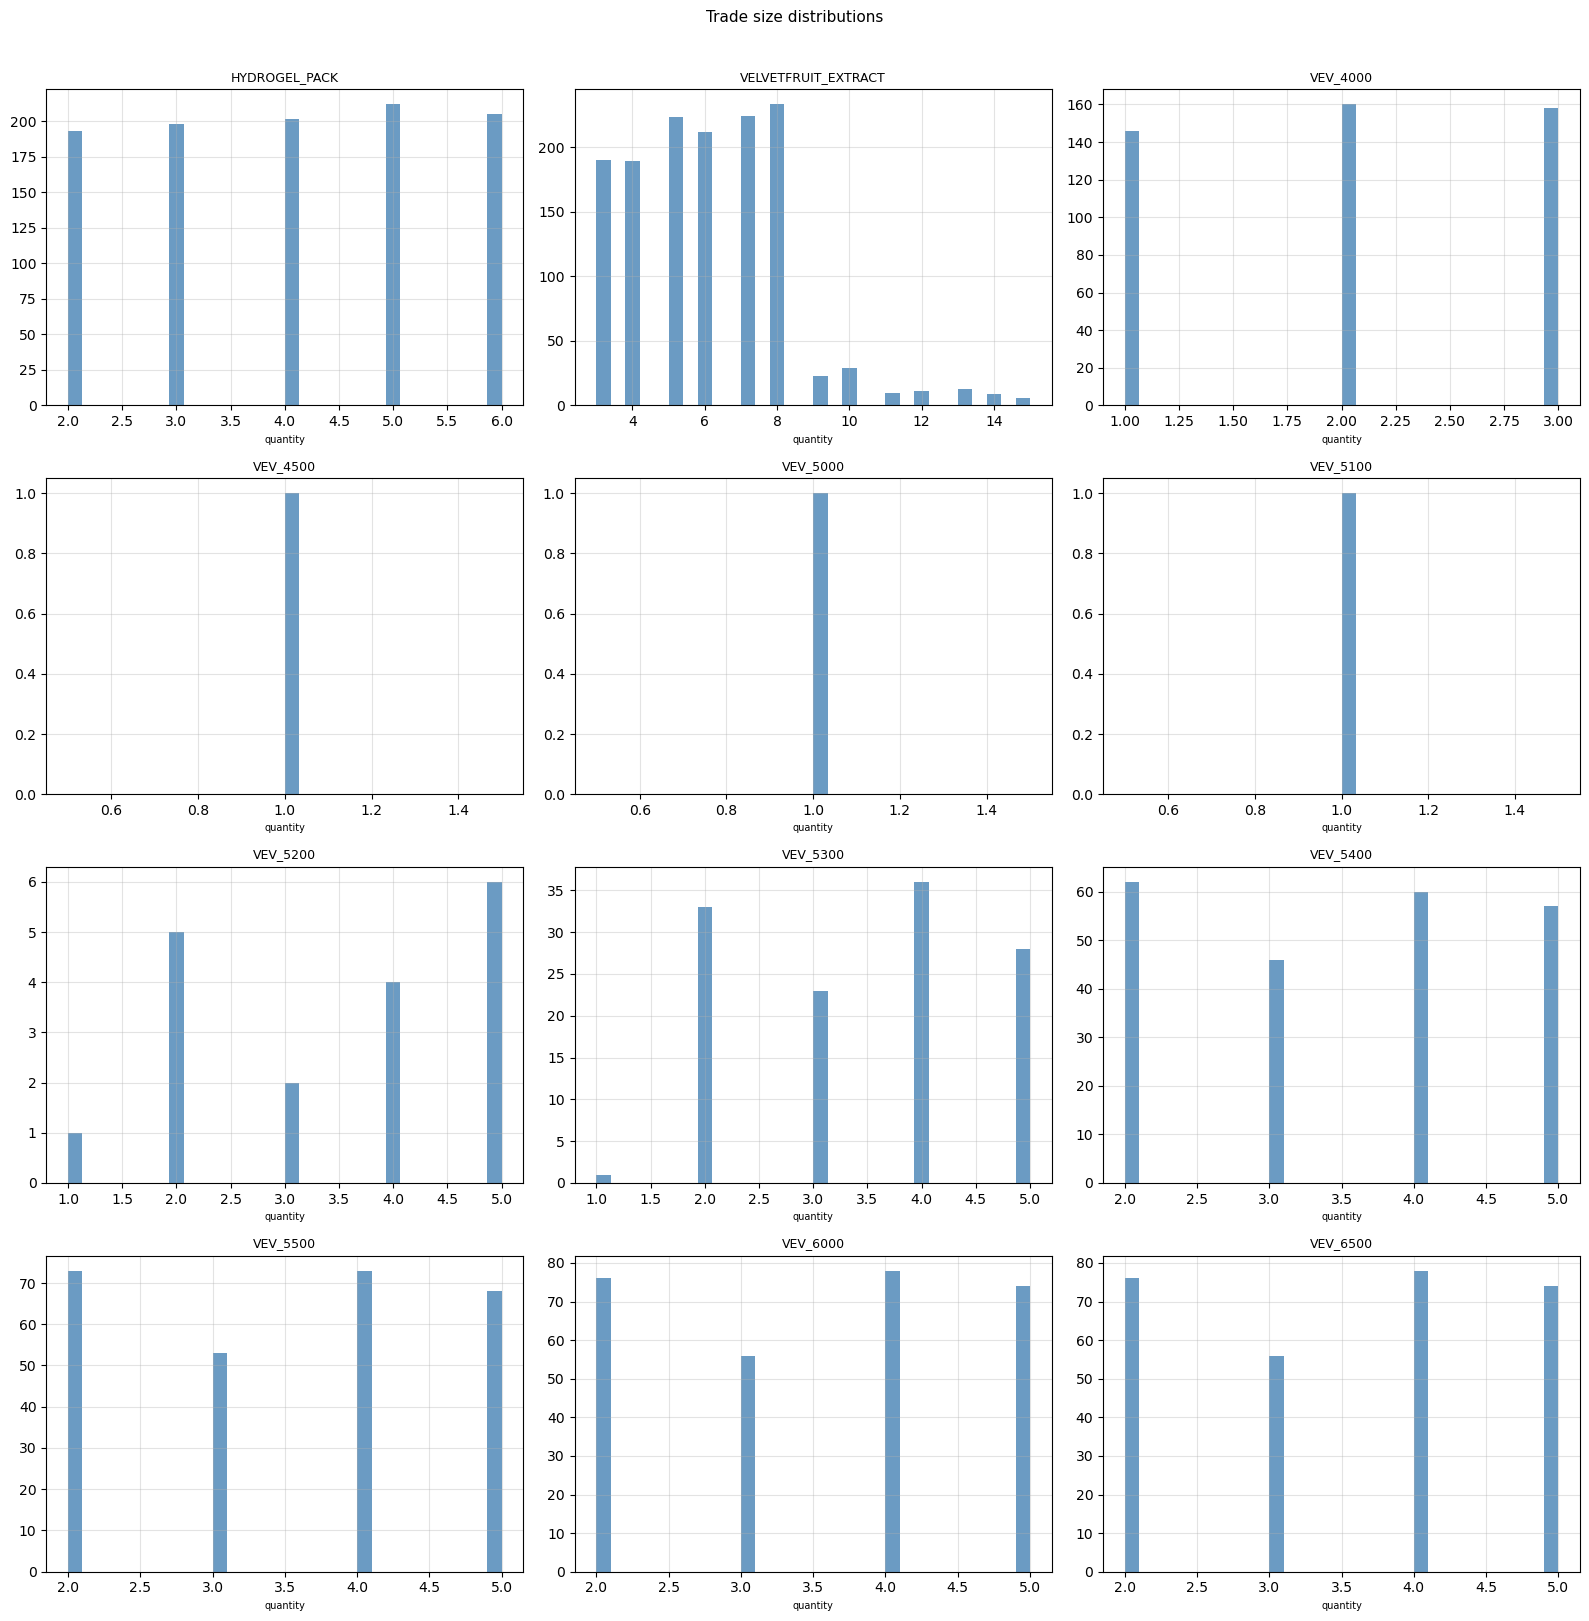

In [94]:
trade_prods = sorted(trades['symbol'].unique())
n = len(trade_prods)
fig, axes = plt.subplots(math.ceil(n/3), 3, figsize=(16, 4*math.ceil(n/3)))
axes = axes.flatten()
for i, prod in enumerate(trade_prods):
    t = trades[trades['symbol'] == prod]['quantity'].dropna()
    axes[i].hist(t, bins=30, color='steelblue', edgecolor='none', alpha=0.8)
    axes[i].set_title(prod, fontsize=9)
    axes[i].set_xlabel("quantity", fontsize=7)
for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle("Trade size distributions", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()


**Section 10 takeaways — Trade Activity:**
- Volume summary shows which products actually traded and how much. Low-volume products have noisier price signals.
- Trade price vs mid-price chart: red dots = actual fills. Dots clustering on mid = tight execution. Dots systematically above/below mid = market orders crossing the spread.
- Trade size distributions: narrow distributions = algorithmic steady flow. Wide or bimodal = mix of small market-making fills and occasional large directional trades.
- Sparsely traded options (VEV_6000, VEV_6500) should be treated with skepticism — prices may be stale or driven by single large orders.

## 11. Options Strategy Signals

Six graphs directly useful for building a trading strategy: execution cost, mispricings, IV persistence, cross-strike structure, and realized vs implied vol.

### 11a. Bid-Ask Spread per Option Strike
Execution cost. If the spread is wider than the expected mis-pricing, the trade is not worth taking.

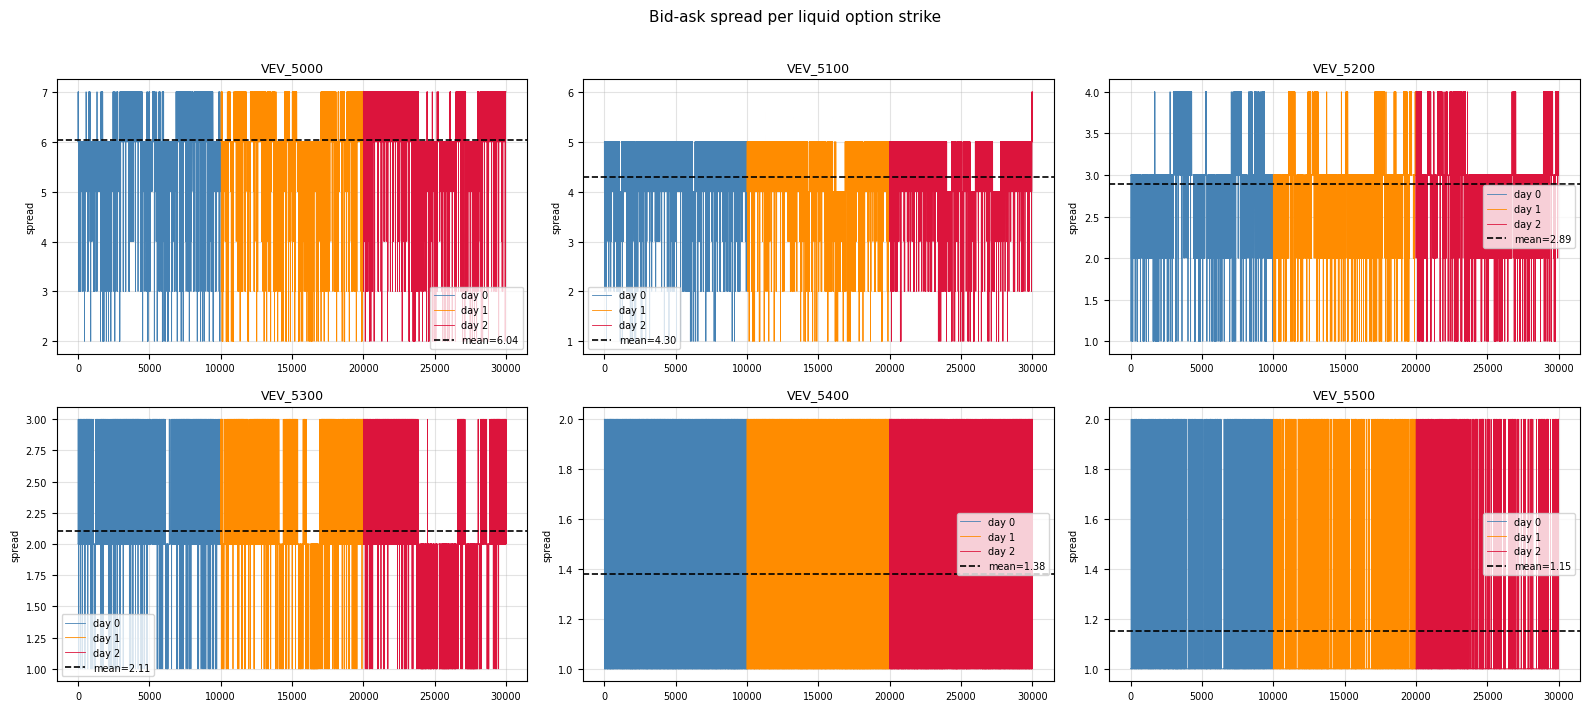

Mean bid-ask spread per strike:
  VEV_5000: mean=6.04  median=6.00  max=7.00
  VEV_5100: mean=4.30  median=4.00  max=6.00
  VEV_5200: mean=2.89  median=3.00  max=4.00
  VEV_5300: mean=2.11  median=2.00  max=3.00
  VEV_5400: mean=1.38  median=1.00  max=2.00
  VEV_5500: mean=1.15  median=1.00  max=2.00


In [95]:
n_cols = 3
n_rows = math.ceil(len(iv_liquid) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = axes.flatten()

for i, k in enumerate(iv_liquid):
    opt = prices[prices['product'] == f'VEV_{k}'].copy()
    opt['spread'] = opt['ask_price_1'] - opt['bid_price_1']
    for day in train_days:
        seg = opt[opt['day'] == day]
        axes[i].plot(seg['gx'], seg['spread'], color=DAY_COLORS[day],
                     linewidth=0.6, label=f'day {day}')
    mean_spread = opt['spread'].mean()
    axes[i].axhline(mean_spread, color='black', linewidth=1.2, linestyle='--',
                    label=f'mean={mean_spread:.2f}')
    axes[i].set_title(f'VEV_{k}', fontsize=9)
    axes[i].set_ylabel('spread', fontsize=7)
    axes[i].tick_params(labelsize=7)
    axes[i].legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Bid-ask spread per liquid option strike", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

# Summary table
print("Mean bid-ask spread per strike:")
for k in iv_liquid:
    opt = prices[prices['product'] == f'VEV_{k}']
    sp  = (opt['ask_price_1'] - opt['bid_price_1']).dropna()
    print(f"  VEV_{k}: mean={sp.mean():.2f}  median={sp.median():.2f}  max={sp.max():.2f}")

### 11b. BS Residual (Market Price - Model Price)
Uses the per-day mean IV as the "fair" model. Positive residual = option is overpriced vs model; negative = underpriced. These are the raw mispricings we would trade.

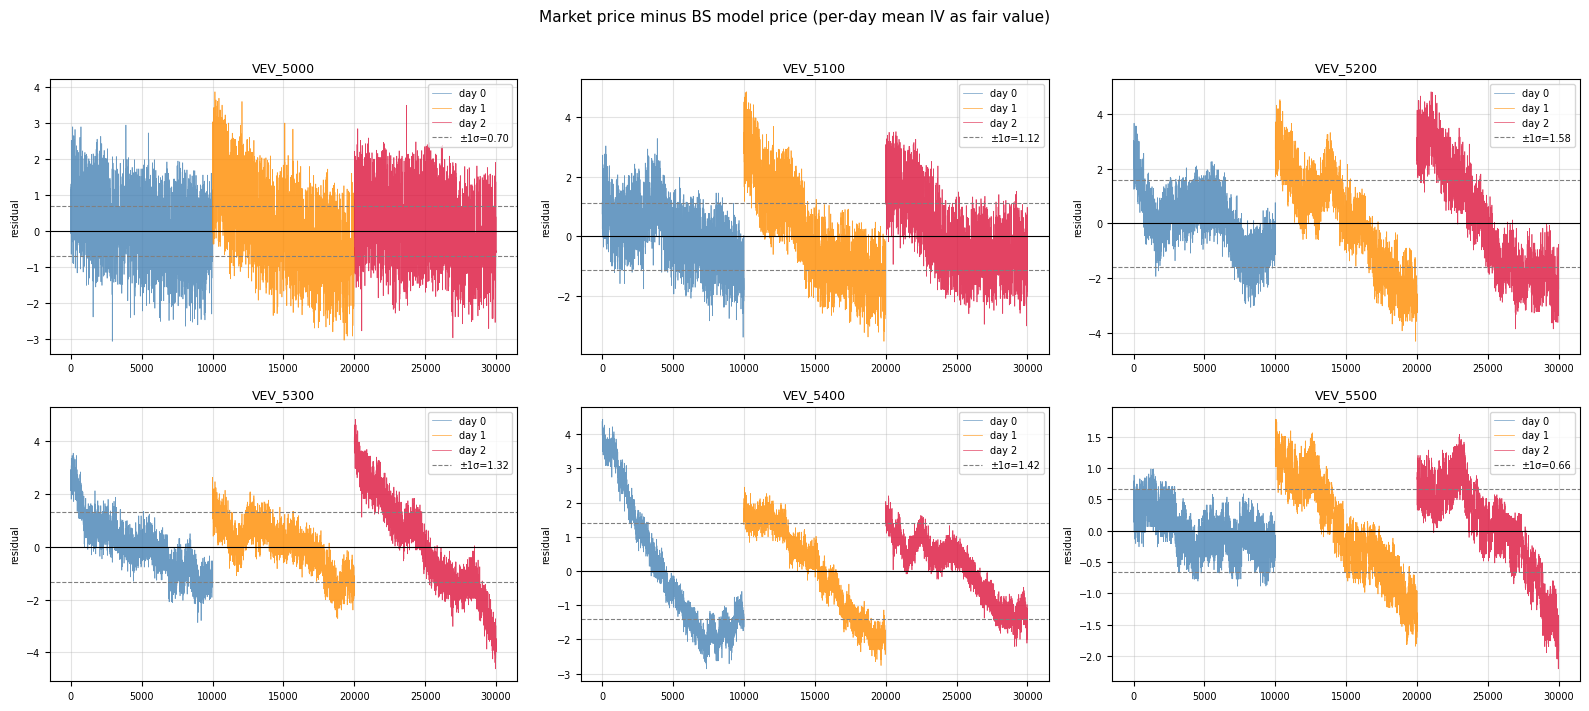

In [96]:
# Per-day mean IV per strike as the "fair" benchmark
day_iv_mean = {}
for k in iv_liquid:
    day_iv_mean[k] = iv_data[k].groupby('day')['IV'].mean().to_dict()

n_cols = 3
n_rows = math.ceil(len(iv_liquid) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = axes.flatten()

for i, k in enumerate(iv_liquid):
    df = iv_data[k].copy()
    df['fair_iv']  = df['day'].map(day_iv_mean[k])
    df['fair_iv']  = df['fair_iv'].fillna(df['fair_iv'].mean())
    df['model_px'] = [bs_call(r['S'], k, T_REF, r['fair_iv'])
                      if pd.notna(r['S']) and r['fair_iv'] > 0 else np.nan
                      for _, r in df.iterrows()]
    df['residual'] = df['mid_price'] - df['model_px']

    for day in train_days:
        seg = df[df['day'] == day]
        axes[i].plot(seg['gx'], seg['residual'], color=DAY_COLORS[day],
                     linewidth=0.5, alpha=0.8, label=f'day {day}')

    axes[i].axhline(0, color='black', linewidth=0.8)
    res_std = df['residual'].std()
    axes[i].axhline( res_std, color='gray', linewidth=0.8, linestyle='--', label=f'±1σ={res_std:.2f}')
    axes[i].axhline(-res_std, color='gray', linewidth=0.8, linestyle='--')
    axes[i].set_title(f'VEV_{k}', fontsize=9)
    axes[i].set_ylabel('residual', fontsize=7)
    axes[i].tick_params(labelsize=7)
    axes[i].legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Market price minus BS model price (per-day mean IV as fair value)", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

### 11c. IV Rolling Mean + Bands (±1 std)
Rolling 300-tick window. The bands show the "normal" IV range at each point in time. Excursions outside the bands are the potential entry signals for an IV mean-reversion strategy.

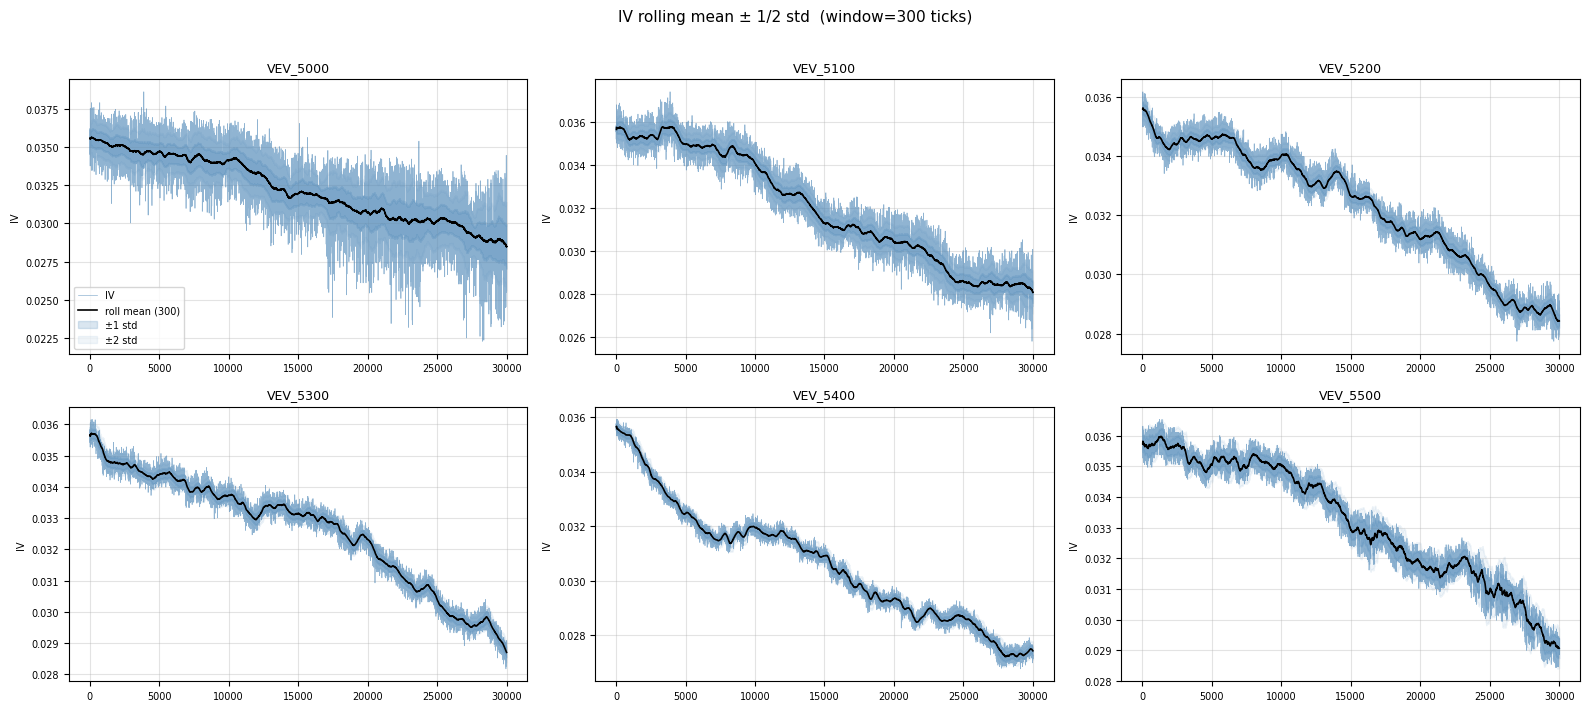

In [97]:
ROLL_WIN = 300

n_cols = 3
n_rows = math.ceil(len(iv_liquid) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = axes.flatten()

for i, k in enumerate(iv_liquid):
    iv = iv_data[k]['IV']
    gx = iv_data[k]['gx']
    rm   = iv.rolling(ROLL_WIN, min_periods=30).mean()
    rstd = iv.rolling(ROLL_WIN, min_periods=30).std()

    axes[i].plot(gx, iv,       color='steelblue', linewidth=0.5, alpha=0.6, label='IV')
    axes[i].plot(gx, rm,       color='black',     linewidth=1.2, label=f'roll mean ({ROLL_WIN})')
    axes[i].fill_between(gx, rm - rstd, rm + rstd, alpha=0.2, color='steelblue', label='±1 std')
    axes[i].fill_between(gx, rm - 2*rstd, rm + 2*rstd, alpha=0.08, color='steelblue', label='±2 std')

    axes[i].set_title(f'VEV_{k}', fontsize=9)
    axes[i].set_ylabel('IV', fontsize=7)
    axes[i].tick_params(labelsize=7)
    if i == 0:
        axes[i].legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f"IV rolling mean ± 1/2 std  (window={ROLL_WIN} ticks)", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

### 11d. IV Autocorrelation per Strike
If IV at lag 1 is strongly positive, it is persistent (trending). If it decays slowly, a rolling-mean reversion strategy has time to work before the signal disappears. Each subplot = one strike.

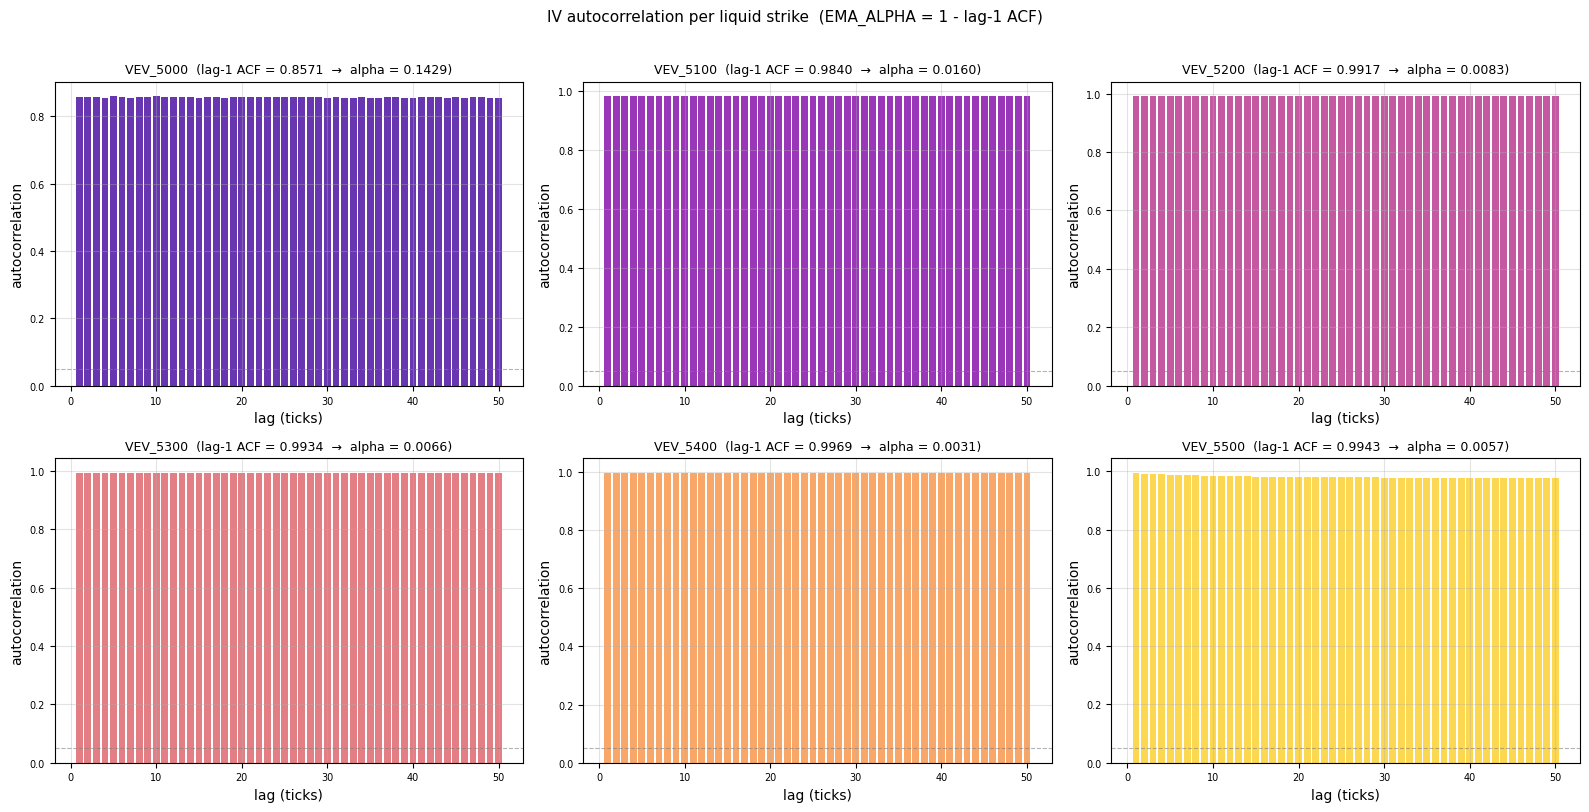


Suggested EMA_ALPHA per strike (= 1 - lag-1 autocorrelation):
  VEV_5000: lag-1 ACF = 0.8571  →  alpha = 0.1429
  VEV_5100: lag-1 ACF = 0.9840  →  alpha = 0.0160
  VEV_5200: lag-1 ACF = 0.9917  →  alpha = 0.0083
  VEV_5300: lag-1 ACF = 0.9934  →  alpha = 0.0066
  VEV_5400: lag-1 ACF = 0.9969  →  alpha = 0.0031
  VEV_5500: lag-1 ACF = 0.9943  →  alpha = 0.0057

  Mean alpha across strikes: 0.0304
  Min  alpha (most conservative): 0.0031


In [98]:

max_lag = 50

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, k in enumerate(iv_liquid):
    iv = iv_data[k]['IV'].dropna()
    lags = range(1, max_lag + 1)
    acf  = [iv.autocorr(lag) for lag in lags]

    axes[i].bar(list(lags), acf, color=colors_iv[i], alpha=0.8)
    axes[i].axhline(0,    color='black', linewidth=0.5)
    axes[i].axhline(0.05, color='gray',  linewidth=0.8, linestyle='--', alpha=0.6)
    axes[i].set_title(f'VEV_{k}  (lag-1 ACF = {acf[0]:.4f}  →  alpha = {1 - acf[0]:.4f})', fontsize=9)
    axes[i].set_xlabel('lag (ticks)'); axes[i].set_ylabel('autocorrelation')
    axes[i].tick_params(labelsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("IV autocorrelation per liquid strike  (EMA_ALPHA = 1 - lag-1 ACF)", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

print("\nSuggested EMA_ALPHA per strike (= 1 - lag-1 autocorrelation):")
alphas = []
for k in iv_liquid:
    iv = iv_data[k]['IV'].dropna()
    a1 = iv.autocorr(1)
    alpha = 1 - a1
    alphas.append(alpha)
    print(f"  VEV_{k}: lag-1 ACF = {a1:.4f}  →  alpha = {alpha:.4f}")
print(f"\n  Mean alpha across strikes: {np.mean(alphas):.4f}")
print(f"  Min  alpha (most conservative): {np.min(alphas):.4f}")


In [109]:
print(df.shape)
print(df['product'].value_counts())

(30000, 23)
product
VEV_5500    30000
Name: count, dtype: int64


In [110]:
from sklearn.linear_model import LinearRegression
import numpy as np

OPT_MAX_DAYS = 7

for K in [5100, 5200, 5300, 5400, 5500]:
    opt = prices[prices['product'] == f'VEV_{K}'].set_index(['day', 'timestamp'])['mid_price']
    sub = pd.DataFrame({'C': opt, 'S': S_idx}).dropna().reset_index()
    sub = sub[sub['C'] > 0]
    days_rem = OPT_MAX_DAYS - sub['day']
    m = sub['S'] - K
    X = np.column_stack([m, days_rem, m**2])
    y = sub['C']
    reg = LinearRegression().fit(X, y)
    b, (mc, dc, m2c) = reg.intercept_, reg.coef_
    print(f"{K}: ({b:.4f}, {mc:.4f}, {dc:.4f}, {m2c:.6f}),")

5100: (30.7077, 0.6464, 4.1338, 0.000627),
5200: (38.8591, 0.5599, 4.4991, 0.000597),
5300: (43.2072, 0.4246, 3.9257, 0.000434),
5400: (29.8800, 0.2727, 3.1140, 0.000364),
5500: (12.2952, 0.0519, 1.7156, -0.000048),
